# Matrix metric simulator — two selection trials

Edit the grouped parameters, then **Run All**. Implementation remains collapsed in this notebook.

Each comparison shows **all candidates → A: original-style lag modes → B: ordered + related pairs**. Only retained regions are shown in the selection panels, with their individual cyan curves and selected magenta lag lines. This is an experimental comparison, not a validated selection method.

Minimum displacement remains the baseline for the existing 20% improvement rule. The two selectors act afterward and do not change that calculation.

## 1. Simulation parameters

In [45]:
SIMULATION_UTILS_PATH = None  # Optional absolute path to the original simulation_utils.py.

SCENARIOS = ["easy_agreement", "pure_displacement", "width_mismatch",
             "local_agreement_plus_unrelated", "broad_signal_plus_peak",
             "local_anticorrelation", "multiple_correspondences", "tie", "custom"]
n_windows_per_scenario = 2
seed = 4172
simulation_parameters = dict(signal_level=0.75, signal_variation=0.15, noise_level=0.005,
    peak_count_range=(1, 3), unrelated_peak_count_range=(1, 3), location_range=(20, 280),
    width_range=(6, 24), displacement_range=(5, 30), tie_displacement_range=(30, 90),
    tie_strength_variation=0.03, shape_a="bell", shape_b="bell", n=300)
# The seven deterministic controls are added after these random scenarios.

## 2. Shape and combination

In [46]:
SHAPE_PARAMETERS = dict(sigma=2.0, halfwidths=(8, 16), slope_weight=0.5, structure_floor=0.02)
shape_strength = 0.5

## 3. Seeding and extending

In [47]:
CANDIDATE_PARAMETERS = dict(seed_threshold_fraction=0.4, growth_threshold_fraction=0.3,
                            max_weak_distance=2, gap_tolerance=1)

## 4. Splitting

In [48]:
SPLIT_PARAMETERS = dict(split_prominence_fraction=0.3, split_min_peak_fraction=0.5,
                       split_min_peak_distance=8, split_min_seed_area=5)

## 5. Quantile curves

No additional marginal smoothing at the current settings.

In [49]:
QUANTILE_PARAMETERS = dict(n_points=128, signal_influence=1.0, signal_power=1.0,
                           smoothing_sigma=0.0)

## 6. Displacement improvement threshold

**`minimum_relative_gain`** is the extra diagonal support required to leave the minimum-|lag| baseline.

- Current setting: `0.2` means **more than 20% improvement**.
- `0.05` means more than 5%; `0` accepts any improvement beyond numerical ties.
- A tie retains the baseline. If a move is justified, equally best diagonals favor the smallest absolute displacement.

This is an adjustable effect-size threshold, not a statistical significance test. It is applied separately to each candidate and to each matrix.

In [50]:
DISPLACEMENT_PARAMETERS = dict(minimum_relative_gain=0.2)  # Require more than 20% gain over minimum-|lag|.

## 7. Selection trials

**A · Original-style lag modes:** reuse the original grouping, area/shape score, zero-lag conflict gate, and relative mode-score cutoff. The original geometric ridge intervals are used internally for grouping only; no ridges are drawn. Modes select candidates; they do not merge their quantile curves.

**B · Ordered + related pairs:** maximize a sum of selected-diagonal support plus a zero-lag bonus, using an order-preserving chain of matched A/B intervals. Each candidate can have a different lag. Optional opposite-lag pairs with shared signal and overlapping matched footprints can be retained together as a related configuration. This is a provisional protection for anti-correlation-like structure, not an anti-correlation detector.

Both trials return subsets of the same candidates. No candidate masks, quantile curves, selected lags, or production files are changed.

In [51]:
LEGACY_SELECTION_PARAMETERS = dict(ridge_fraction=0.9, shape_balance_power=1.05,
    displacement_fold_threshold=2.0, mode_score_fraction=0.33)

ORDERED_SELECTION_PARAMETERS = dict(zero_lag_bonus=1.0, preserve_straddling_pairs=True)
# Weight = selected_diagonal_score + zero_lag_bonus * zero_lag_score.
# Set preserve_straddling_pairs=False to inspect the strict ordered-chain version.

## 8. Display settings

In [52]:
matrix_windows_per_scenario = 1
candidate_stage = "split"  # "split" or "unsplit".
PLOT_SCENARIOS = None  # None = all; or ["two_peak_perfect_agreement", "clean_local_anticorrelation"].

SHOW_SELECTION_COMPARISONS = True
SELECTION_MATRICES = ("combined",)  # Or ("minimum", "combined").
SHOW_MATRIX_OVERVIEW = False  # Previous minimum / shape / combined view.
SHOW_TRACK_OVERVIEW = False  # Tracks are also included beside every comparison panel.
SHOW_DISPLACEMENT_PROFILES = False

SHOW_CANDIDATE_DIAGNOSTICS = False
SHOW_REGION_IDS = False
SHOW_ZERO_LAG_SUPPORT = False

## Implementation — collapsed

No edits normally needed. The notebook remains self-contained apart from the original `simulation_utils.py`.

In [53]:
from pathlib import Path
from time import perf_counter
import importlib.util
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.ndimage import gaussian_filter1d
from numpy.lib.stride_tricks import sliding_window_view

from scipy.signal import find_peaks
import pandas as pd
from matplotlib.lines import Line2D


def load_simulator(path):
    if path is None:
        candidates = [Path.cwd() / "simulation_utils.py", Path.home() / "Downloads" / "simulation_utils.py"]
        spec = importlib.util.find_spec("simulation_utils")
        if spec is not None and spec.origin:
            candidates.insert(0, Path(spec.origin))
        path = next((candidate for candidate in candidates if candidate.is_file()), None)
    if path is None:
        raise FileNotFoundError("Set SIMULATION_UTILS_PATH to the original simulation_utils.py.")
    path = Path(path).expanduser().resolve()
    spec = importlib.util.spec_from_file_location("simulation_utils", path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    print(f"Simulator: {path}")
    return module


def generate_windows():
    scenarios = SCENARIOS.copy()
    rng = np.random.default_rng(seed)
    windows = {scenario: [simulation_utils.simulate_pair(scenario, rng, **simulation_parameters)
                         for _ in range(n_windows_per_scenario)] for scenario in scenarios}

    # Change only the dominant track inside a region above the entire weaker track.
    x = np.arange(simulation_parameters["n"], dtype=float)
    center = 150
    core_radius = 42
    weak = 0.06 + simulation_utils.gaussian(x, center, 14, height=0.65)
    pedestal = simulation_utils.plateau(x, center, 120, edge=5, height=weak.max() + 0.35)
    t = (x - center) / core_radius
    taper = np.maximum(1 - t**2, 0)**2
    single = simulation_utils.gaussian(x, center, 14) * taper
    double = (simulation_utils.gaussian(x, center - 22, 8)
              + simulation_utils.gaussian(x, center + 22, 8)) * taper
    dominant_peak = pedestal + 1.2 * single / single.max()
    dominant_valley = pedestal + 1.2 * double / double.max()
    changed = dominant_peak != dominant_valley
    assert np.all(pedestal[changed] > weak.max())

    windows["dominant_peak_alignment"] = [(weak.copy(), dominant_peak)]
    windows["dominant_valley_alignment"] = [(weak.copy(), dominant_valley)]
    scenarios += ["dominant_peak_alignment", "dominant_valley_alignment"]
    # Off-center peaks still overlap the broad track at their native positions.
    broad = np.full_like(x, 0.9)
    for name, peak_center in (("broad_signal_peak_left", 55), ("broad_signal_peak_right", 245)):
        peak = 0.03 + simulation_utils.gaussian(x, peak_center, 14, height=0.8)
        windows[name] = [(broad.copy(), peak)]
        scenarios.append(name)

    # A line can touch zero lag despite a clear difference between peak centers.
    broad_shifted = 0.02 + simulation_utils.gaussian(x, 85, 45, height=0.85)
    narrow_shifted = 0.02 + simulation_utils.gaussian(x, 125, 10, height=0.75)
    windows["shifted_width_minimum_lag_trap"] = [(broad_shifted, narrow_shifted)]
    scenarios.append("shifted_width_minimum_lag_trap")
    displacement_test_scenarios = [
        "broad_signal_peak_left", "broad_signal_peak_right", "shifted_width_minimum_lag_trap"]

    # Clean selection controls do not consume the original random stream.
    paired = (0.02 + simulation_utils.gaussian(x, 90, 10, height=0.8)
              + simulation_utils.gaussian(x, 210, 13, height=0.75))
    windows["two_peak_perfect_agreement"] = [(paired.copy(), paired.copy())]
    anti_a = 0.02 + simulation_utils.gaussian(x, 150, 14, height=0.8)
    anti_b = 0.85 - simulation_utils.gaussian(x, 150, 20, height=0.78)
    windows["clean_local_anticorrelation"] = [(anti_a, anti_b)]
    scenarios += ["two_peak_perfect_agreement", "clean_local_anticorrelation"]
    return windows, scenarios, dict(center=center, displacement_test_scenarios=displacement_test_scenarios)


def plot_simulated_tracks():
    fig, axes = plt.subplots(len(scenarios), n_windows_per_scenario,
        figsize=(12, 2.1 * len(scenarios)), sharex=True, squeeze=False)
    for row, scenario in enumerate(scenarios):
        for col in range(n_windows_per_scenario):
            ax = axes[row, col]
            if col >= len(windows[scenario]):
                ax.set_visible(False)
                continue
            a, b = windows[scenario][col]
            ax.plot(a, label="A")
            ax.plot(b, label="B")
            ax.set(title=f"{scenario} — {col}", ylim=(0, None))
            ax.legend(loc="upper right")
    for ax in axes[-1]:
        if ax.get_visible():
            ax.set_xlabel("Position (nt)")
    fig.tight_layout()
    plt.show()
    return fig


def local_shape_features(signal, radius, sigma, slope_weight, structure_floor):
    smooth = gaussian_filter1d(signal, sigma, mode="reflect")
    slope = gaussian_filter1d(signal, sigma, order=1, mode="reflect")
    offsets = np.arange(-radius, radius + 1)
    weights = np.exp(-0.5 * (offsets / max(radius / 2, 1))**2)
    weights /= weights.sum()
    profile = sliding_window_view(np.pad(smooth, radius, mode="reflect"), 2 * radius + 1)
    gradient = sliding_window_view(np.pad(slope, radius, mode="reflect"), 2 * radius + 1)
    centered = profile - (profile @ weights)[:, None]
    features = np.concatenate((np.sqrt(1 - slope_weight) * centered * np.sqrt(weights),
                               np.sqrt(slope_weight) * radius * gradient * np.sqrt(weights)), axis=1)
    norm = np.sqrt(np.sum(features**2, axis=1) + structure_floor**2)
    return features / norm[:, None]

def shape_matrix(a, b, sigma=2.0, halfwidths=(8, 16), slope_weight=0.5, structure_floor=0.02):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    if any(s.ndim != 1 or len(s) < 2 or not np.isfinite(s).all() for s in (a, b)):
        raise ValueError("Tracks must be finite 1D arrays with at least two positions.")
    if sigma <= 0 or not 0 <= slope_weight <= 1 or structure_floor <= 0:
        raise ValueError("Require sigma > 0, slope_weight in [0, 1], and structure_floor > 0.")
    if not halfwidths or any(not isinstance(r, (int, np.integer)) or r < 1 for r in halfwidths):
        raise ValueError("halfwidths must contain positive integer radii.")
    scores = []
    for radius in halfwidths:
        features_a = local_shape_features(a, radius, sigma, slope_weight, structure_floor)
        features_b = local_shape_features(b, radius, sigma, slope_weight, structure_floor)
        scores.append(features_a @ features_b.T)
    return np.clip(np.mean(scores, axis=0), -1, 1)

def correspondence_matrices(a, b, shape_strength=0.5, **shape_parameters):
    if not 0 <= shape_strength < 1:
        raise ValueError("shape_strength must be in [0, 1).")
    shape = shape_matrix(a, b, **shape_parameters)
    minimum = np.minimum(np.asarray(a)[:, None], np.asarray(b)[None, :])
    if np.any(minimum < 0):
        raise ValueError("Minimum support requires nonnegative tracks.")
    return dict(minimum=minimum, shape=shape, combined=minimum * (1 + shape_strength * shape))



def candidate_regions(matrix, seed_threshold_fraction=0.4, growth_threshold_fraction=0.3,
                      max_weak_distance=2, gap_tolerance=1):
    """Label unsplit regions using the original seed-and-extend method."""
    max_value = matrix.max()
    seed_threshold = seed_threshold_fraction * max_value
    growth_threshold = growth_threshold_fraction * max_value
    if max_value <= 0:
        empty = np.zeros_like(matrix, dtype=bool)
        return dict(seed_mask=empty, candidate_mask=empty.copy(),
                    labels=np.zeros_like(matrix, dtype=np.int32), n_candidates=0,
                    seed_threshold=seed_threshold, growth_threshold=growth_threshold)

    seed_mask = matrix > seed_threshold
    growth_mask = matrix > growth_threshold
    if gap_tolerance > 0:
        growth_mask = ndimage.binary_closing(growth_mask, structure=np.ones((3, 3)),
                                            iterations=gap_tolerance)

    # Extend into nearby growth support, then restore all seeds.
    distance_from_seed = ndimage.distance_transform_edt(~seed_mask)
    candidate_mask = growth_mask & (distance_from_seed <= max_weak_distance)
    candidate_mask |= seed_mask
    candidate_mask = ndimage.binary_fill_holes(candidate_mask)
    labels, n_candidates = ndimage.label(candidate_mask, structure=np.ones((3, 3)))
    return dict(seed_mask=seed_mask, candidate_mask=candidate_mask, labels=labels,
                n_candidates=n_candidates, seed_threshold=seed_threshold,
                growth_threshold=growth_threshold)



def best_island_split(matrix, region, seed_mask, split_prominence_fraction=0.25, split_min_peak_fraction=0.5, split_min_peak_distance=8, split_min_seed_area=5):
    """
    Find the strongest valid island-local valley along either axis.
    """
    rows = np.flatnonzero(region.any(axis=1))
    columns = np.flatnonzero(region.any(axis=0))
    if not len(rows) or not len(columns):
        return None
    crop = np.s_[rows[0]:rows[-1] + 1, columns[0]:columns[-1] + 1]
    local_region = region[crop]
    masked = np.where(local_region, matrix[crop], -np.inf)
    local_seeds = seed_mask[crop] & local_region
    best = None

    for axis, positions, offset, reduction_axis in (
        ("A", rows, rows[0], 1), ("B", columns, columns[0], 0)
    ):
        profile = masked.max(axis=reduction_axis)[positions - offset]
        
        if len(profile) < 2 * split_min_peak_distance + 1:
            continue

        peaks, _ = find_peaks(profile, distance=split_min_peak_distance)

        if len(peaks) < 2:
            continue

        peaks = peaks[profile[peaks] >= split_min_peak_fraction * profile.max()]

        cumulative_seeds = np.cumsum(np.count_nonzero(local_seeds, axis=reduction_axis))

        for left_peak, right_peak in zip(peaks[:-1], peaks[1:]):

            valley_segment = profile[left_peak:right_peak + 1]
            valley = left_peak + int(np.argmin(valley_segment))

            smaller_peak = min(profile[left_peak], profile[right_peak])
            valley_depth = 1 - profile[valley] / smaller_peak if smaller_peak > 0 else 0.0
            if valley_depth < split_prominence_fraction:
                continue

            cut = int(positions[valley])
            seed_area_1 = int(cumulative_seeds[cut - offset])
            seed_area_2 = int(cumulative_seeds[-1]) - seed_area_1
            if seed_area_1 < split_min_seed_area or seed_area_2 < split_min_seed_area:
                continue

            key = (float(valley_depth), float(smaller_peak))
            if best is None or key > best[0]:
                best = (key, axis, cut)

    if best is None:
        return None

    key, axis, cut = best
    coordinates = np.arange(region.shape[0])[:, None] if axis == "A" else np.arange(region.shape[1])[None, :]
    return {"valley_depth": key[0], "smaller_peak": key[1],
            "children": (region & (coordinates <= cut), region & (coordinates > cut))}

def split_island_region(matrix, region, seed_mask, split_prominence_fraction=0.25, split_min_peak_fraction=0.5, split_min_peak_distance=8, split_min_seed_area=5):
    """Recursively split an overmerged island at its strongest valid axis valley."""
    pending = [region]
    finished = []

    while pending:
        current = pending.pop()
        split = best_island_split(matrix, current, seed_mask, split_prominence_fraction=split_prominence_fraction,
                                  split_min_peak_fraction=split_min_peak_fraction, split_min_peak_distance=split_min_peak_distance,
                                  split_min_seed_area=split_min_seed_area)
        if split is None:
            finished.append(current)
        else:
            pending.extend(split["children"])

    return finished

def split_candidate_regions(matrix, candidates, **split_parameters):
    """Split each seeded region without changing its supported pixels."""
    labels = np.zeros_like(candidates["labels"])
    parent_region_ids = {}
    next_id = 1
    for parent_id in range(1, candidates["n_candidates"] + 1):
        region = candidates["labels"] == parent_id
        if not np.any(candidates["seed_mask"] & region):
            continue
        children = split_island_region(matrix, region, candidates["seed_mask"], **split_parameters)
        for child in children:
            labels[child] = next_id
            parent_region_ids[next_id] = parent_id
            next_id += 1
    return dict(candidates, labels=labels, n_candidates=next_id - 1,
                unsplit_labels=candidates["labels"], n_unsplit=candidates["n_candidates"],
                parent_region_ids=parent_region_ids)



def mode_crop(array, mode):
    return array[mode["y_min"]:mode["y_max"] + 1, mode["x_min"]:mode["x_max"] + 1]

def weighted_quantile_positions(weights, quantiles):
    """Convert cumulative mass to fractional positions."""
    weights = np.clip(np.asarray(weights, dtype=float), 0, None)
    if weights.sum() == 0:
        weights = np.ones_like(weights)
    cumulative = np.r_[0.0, np.cumsum(weights) / weights.sum()]
    positions = np.linspace(0, len(weights) - 1, len(weights) + 1)
    return np.interp(quantiles, cumulative, positions)

def smooth_marginal(weights, sigma):
    if sigma <= 0:
        return weights
    radius = max(1, int(np.ceil(4 * sigma)))
    offsets = np.arange(-radius, radius + 1)
    kernel = np.exp(-0.5 * (offsets / sigma) ** 2)
    kernel /= kernel.sum()
    return np.convolve(np.pad(weights, radius, mode="edge"), kernel, mode="valid")

def prepare_marginal(weights, signal_influence, smoothing_sigma, support):
    """Blend the observed marginal with uniform supported mass."""
    support = np.asarray(support, dtype=bool)
    weights = smooth_marginal(np.asarray(weights, dtype=float), smoothing_sigma)
    weights = np.where(support, weights, 0)
    uniform = support / support.sum()
    observed = uniform if weights.sum() == 0 else weights / weights.sum()
    return signal_influence * observed + (1 - signal_influence) * uniform

def project_points_to_mask(x, y, mask):
    """Move unsupported points to their nearest valid pixel."""
    valid_rows, valid_columns = np.where(mask)
    if len(valid_rows) == 0:
        raise ValueError("Cannot project onto an empty mode mask.")
    projected_x = np.asarray(x, dtype=float).copy()
    projected_y = np.asarray(y, dtype=float).copy()
    rounded_x = np.rint(projected_x).astype(int)
    rounded_y = np.rint(projected_y).astype(int)
    in_bounds = ((rounded_x >= 0) & (rounded_x < mask.shape[1])
                 & (rounded_y >= 0) & (rounded_y < mask.shape[0]))
    valid = np.zeros(len(projected_x), dtype=bool)
    valid[in_bounds] = mask[rounded_y[in_bounds], rounded_x[in_bounds]]
    for index in np.where(~valid)[0]:
        distances = (valid_columns - projected_x[index]) ** 2 + (valid_rows - projected_y[index]) ** 2
        nearest = int(np.argmin(distances))
        projected_x[index], projected_y[index] = valid_columns[nearest], valid_rows[nearest]
    return projected_x, projected_y

def quantile_matching_line(matrix, mode, n_points=128, signal_influence=1.0, signal_power=1.0, smoothing_sigma=0.0):
    if not 0 <= signal_influence <= 1 or signal_power <= 0 or n_points < 3:
        raise ValueError("Check signal_influence, signal_power, and n_points.")
    crop = mode_crop(matrix, mode)
    mask_crop = mode_crop(mode["mask"], mode)
    positive_crop = np.where(mask_crop, np.clip(crop, 0, None), 0)
    peak = positive_crop.max()
    weighted_crop = (positive_crop / peak) ** signal_power if peak > 0 else positive_crop
    b_marginal = prepare_marginal(weighted_crop.sum(axis=0), signal_influence, smoothing_sigma, mask_crop.any(axis=0))
    a_marginal = prepare_marginal(weighted_crop.sum(axis=1), signal_influence, smoothing_sigma, mask_crop.any(axis=1))
    quantiles = np.linspace(0, 1, n_points)
    x = weighted_quantile_positions(b_marginal, quantiles) + mode["x_min"]
    y = weighted_quantile_positions(a_marginal, quantiles) + mode["y_min"]
    return project_points_to_mask(x, y, mode["mask"])

def clip_infinite_line_to_mask(center, direction, mask):
    """Return the pieces of an infinite line lying inside True mask pixels."""
    center = np.asarray(center, dtype=float)
    direction = np.asarray(direction, dtype=float)
    norm = np.linalg.norm(direction)
    if norm == 0:
        raise ValueError('Cannot clip a line with zero direction.')
    direction = direction / norm

    intervals = []
    rows, columns = np.where(mask)
    tolerance = 1e-10

    # Treat each valid nucleotide as a one-by-one square centered on its index.
    for row, column in zip(rows, columns):
        lower, upper = -np.inf, np.inf
        for coordinate, velocity, minimum, maximum in (
            (center[0], direction[0], column - 0.5, column + 0.5),
            (center[1], direction[1], row - 0.5, row + 0.5),
        ):
            if abs(velocity) <= tolerance:
                if not minimum <= coordinate <= maximum:
                    lower, upper = 1, 0
                    break
            else:
                first = (minimum - coordinate) / velocity
                second = (maximum - coordinate) / velocity
                lower = max(lower, min(first, second))
                upper = min(upper, max(first, second))

        if lower <= upper + tolerance:
            intervals.append((lower, upper))

    if not intervals:
        return np.array([np.nan]), np.array([np.nan])

    intervals.sort()
    merged = [list(intervals[0])]
    for lower, upper in intervals[1:]:
        if lower <= merged[-1][1] + tolerance:
            merged[-1][1] = max(merged[-1][1], upper)
        else:
            merged.append([lower, upper])

    x, y = [], []
    for lower, upper in merged:
        start = center + lower * direction
        end = center + upper * direction
        if x:
            x.append(np.nan)
            y.append(np.nan)
        x.extend([start[0], end[0]])
        y.extend([start[1], end[1]])

    return np.asarray(x), np.asarray(y)

def mask_polyline(x, y, mask):
    """Exactly clip every quantile-curve segment to the True mask pixels."""
    valid_rows, valid_columns = np.where(mask)
    output_x, output_y = [], []
    last_end = None
    tolerance = 1e-10

    for index in range(len(x) - 1):
        start = np.array([x[index], y[index]], dtype=float)
        end = np.array([x[index + 1], y[index + 1]], dtype=float)
        direction = end - start

        # Only pixels whose squares overlap this segment's bounding box can matter.
        candidates = (
            (valid_columns + 0.5 >= min(start[0], end[0]))
            & (valid_columns - 0.5 <= max(start[0], end[0]))
            & (valid_rows + 0.5 >= min(start[1], end[1]))
            & (valid_rows - 0.5 <= max(start[1], end[1]))
        )
        intervals = []

        for row, column in zip(valid_rows[candidates], valid_columns[candidates]):
            lower, upper = 0.0, 1.0
            for coordinate, velocity, minimum, maximum in (
                (start[0], direction[0], column - 0.5, column + 0.5),
                (start[1], direction[1], row - 0.5, row + 0.5),
            ):
                if abs(velocity) <= tolerance:
                    if not minimum <= coordinate <= maximum:
                        lower, upper = 1, 0
                        break
                else:
                    first = (minimum - coordinate) / velocity
                    second = (maximum - coordinate) / velocity
                    lower = max(lower, min(first, second))
                    upper = min(upper, max(first, second))

            if lower <= upper + tolerance:
                intervals.append((lower, upper))

        intervals.sort()
        merged = []
        for lower, upper in intervals:
            if merged and lower <= merged[-1][1] + tolerance:
                merged[-1][1] = max(merged[-1][1], upper)
            else:
                merged.append([lower, upper])

        for lower, upper in merged:
            clipped_start = start + lower * direction
            clipped_end = start + upper * direction
            if last_end is None or not np.allclose(last_end, clipped_start):
                if output_x:
                    output_x.append(np.nan)
                    output_y.append(np.nan)
                output_x.append(clipped_start[0])
                output_y.append(clipped_start[1])
            output_x.append(clipped_end[0])
            output_y.append(clipped_end[1])
            last_end = clipped_end

        if not merged:
            last_end = None

    if not output_x:
        return np.array([np.nan]), np.array([np.nan])
    return np.asarray(output_x), np.asarray(output_y)

def minimum_quantile_displacement(x, y, median):
    """Find the smallest absolute B-A lag on the visible piecewise-linear curve."""
    points = np.column_stack((np.asarray(x, dtype=float), np.asarray(y, dtype=float)))
    finite = np.isfinite(points).all(axis=1)
    vertices = points[finite]
    if not len(vertices):
        raise ValueError("The quantile curve has no visible points.")
    adjacent = finite[:-1] & finite[1:]
    start, end = points[:-1][adjacent], points[1:][adjacent]
    direction = end - start
    start_lag = start[:, 0] - start[:, 1]
    lag_change = direction[:, 0] - direction[:, 1]
    fraction = np.divide(-start_lag, lag_change, out=np.zeros_like(start_lag),
                         where=np.abs(lag_change) > 1e-12)

    # Along constant-lag segments, use the point nearest the median.
    parallel = np.abs(lag_change) <= 1e-12
    length_squared = np.sum(direction**2, axis=1)
    projection = np.divide(np.sum((np.asarray(median) - start) * direction, axis=1),
                           length_squared, out=np.zeros_like(length_squared),
                           where=length_squared > 0)
    fraction[parallel] = projection[parallel]
    closest = start + np.clip(fraction, 0, 1)[:, None] * direction
    choices = np.vstack((vertices, closest))
    lags = choices[:, 0] - choices[:, 1]
    minimum_abs = np.min(np.abs(lags))
    ties = np.flatnonzero(np.isclose(np.abs(lags), minimum_abs, rtol=0, atol=1e-10))
    index = ties[np.argmin(np.sum((choices[ties] - np.asarray(median))**2, axis=1))]
    signed_lag = float(lags[index])
    if abs(signed_lag) < 1e-10:
        signed_lag = 0.0
    vertex_lags = vertices[:, 0] - vertices[:, 1]
    return dict(minimum_b=float(choices[index, 0]), minimum_a=float(choices[index, 1]),
                minimum_lag_b_minus_a=signed_lag, minimum_abs_lag_nt=abs(signed_lag),
                quantile_lag_min=float(vertex_lags.min()), quantile_lag_max=float(vertex_lags.max()))

def diagonal_support_profile(matrix, mask):
    """Sum candidate support by B-A lag."""
    rows, columns = np.where(mask)
    offset = matrix.shape[0] - 1
    lags = np.arange(-offset, matrix.shape[1])
    scores = np.bincount(columns - rows + offset, weights=matrix[rows, columns],
                         minlength=len(lags))
    counts = np.bincount(columns - rows + offset, minlength=len(lags))
    return lags, scores, counts

def choose_diagonal_displacement(matrix, mask, minimum, minimum_relative_gain=0.05):
    """Keep minimum-|lag| unless a globally best supported diagonal earns a shift."""
    if not np.isfinite(minimum_relative_gain) or minimum_relative_gain < 0:
        raise ValueError("minimum_relative_gain must be finite and nonnegative.")
    lags, scores, counts = diagonal_support_profile(matrix, mask)
    baseline_lag = minimum["minimum_lag_b_minus_a"]
    baseline_score = float(np.interp(baseline_lag, lags, scores))
    best_score = max(float(scores.max()), baseline_score)
    ties = np.flatnonzero((counts > 0) & np.isclose(scores, best_score, rtol=1e-10, atol=1e-12))

    # Numerical ties favor the smallest shift, then proximity to the baseline.
    best_lag = min((float(lags[i]) for i in ties),
                   key=lambda lag: (abs(lag), abs(lag - baseline_lag), lag),
                   default=baseline_lag)
    if np.isclose(baseline_score, best_score, rtol=1e-10, atol=1e-12):
        best_lag = baseline_lag
    numerical_gain = not np.isclose(best_score, baseline_score, rtol=1e-10, atol=1e-12)
    improved = numerical_gain and best_score > baseline_score * (1 + minimum_relative_gain)
    selected_lag = best_lag if improved else baseline_lag
    relative_gain = ((best_score - baseline_score) / baseline_score if baseline_score > 0
                     else (np.inf if best_score > 0 else 0.0))
    return dict(selected_lag_b_minus_a=float(selected_lag), best_lag_b_minus_a=float(best_lag),
                baseline_diagonal_score=baseline_score, best_diagonal_score=best_score,
                selected_diagonal_score=float(np.interp(selected_lag, lags, scores)),
                best_relative_gain=float(relative_gain),
                displacement_status="improved" if improved else "minimum_retained",
                diagonal_lags=lags, diagonal_scores=scores, diagonal_pixel_counts=counts)

def candidate_quantile_lines(matrix, candidates):
    """Measure each candidate independently using its masked matrix signal."""
    lines = {}
    labels = candidates["labels"]
    for region_id in range(1, candidates["n_candidates"] + 1):
        mask = labels == region_id
        rows, columns = np.where(mask)
        region = dict(mask=mask, x_min=int(columns.min()), x_max=int(columns.max()),
                      y_min=int(rows.min()), y_max=int(rows.max()))
        x, y = quantile_matching_line(matrix, region, **QUANTILE_PARAMETERS)
        quantiles = np.linspace(0, 1, len(x))
        median_b, median_a = project_points_to_mask(
            [np.interp(0.5, quantiles, x)], [np.interp(0.5, quantiles, y)], mask)
        median_b, median_a = float(median_b[0]), float(median_a[0])
        delta_b = region["x_max"] - region["x_min"]
        delta_a = region["y_max"] - region["y_min"]

        # Keep box-relative offset separate from the window-coordinate lag.
        box_offset = np.nan
        if delta_b > 0 and delta_a > 0:
            box_offset = (delta_b * (median_a - region["y_min"])
                          - delta_a * (median_b - region["x_min"])) / np.hypot(delta_b, delta_a)
        visible = mask_polyline(x, y, mask)
        minimum = minimum_quantile_displacement(*visible, median=(median_b, median_a))
        displacement = choose_diagonal_displacement(matrix, mask, minimum, **DISPLACEMENT_PARAMETERS)
        lines[region_id] = dict(
            quantile=(x, y), visible_quantile=visible, **minimum, **displacement,
            displacement_line=clip_infinite_line_to_mask(
                (displacement["selected_lag_b_minus_a"], 0), (1, 1), mask),
            median_b=median_b, median_a=median_a,
            median_lag_b_minus_a=median_b - median_a,
            median_displacement_nt=float(box_offset),
            metric_status="ok" if np.isfinite(box_offset) else "degenerate_box",
            n_pixels=int(mask.sum()),
            parent_region_id=candidates.get("parent_region_ids", {}).get(region_id, region_id))
    return lines



def candidate_lines_for_pair(scenario, window_idx=0, candidate_stage="split"):
    if candidate_stage not in quantile_line_results:
        raise ValueError('candidate_stage must be "split" or "unsplit".')
    key = (scenario, window_idx)
    cache = quantile_line_results[candidate_stage]
    if key not in cache:
        source = candidate_results if candidate_stage == "split" else unsplit_candidate_results
        cache[key] = {name: candidate_quantile_lines(matrix_results[key][name], candidates)
                      for name, candidates in source[key].items()}
    return cache[key]



def interval_order(left_min, left_max, right_min, right_max):
    """Return the strict order of two nonoverlapping intervals, or zero."""
    if left_max < right_min - 1e-10:
        return -1
    if right_max < left_min - 1e-10:
        return 1
    return 0

def selected_line_geometry(line):
    """Return the matched coordinate bounds and an interior label location."""
    x, y = line["displacement_line"]
    points = np.column_stack((x, y))
    finite = np.isfinite(points).all(axis=1)
    valid = points[finite]
    adjacent = finite[:-1] & finite[1:]
    starts, ends = points[:-1][adjacent], points[1:][adjacent]
    if not len(valid):
        raise ValueError("A selected displacement line has no supported segment.")
    if len(starts):
        longest = np.argmax(np.sum((ends - starts)**2, axis=1))
        anchor = (starts[longest] + ends[longest]) / 2
    else:
        anchor = valid[0]
    return dict(matched_a_min=float(valid[:, 1].min()), matched_a_max=float(valid[:, 1].max()),
                matched_b_min=float(valid[:, 0].min()), matched_b_max=float(valid[:, 0].max()),
                label_b=float(anchor[0]), label_a=float(anchor[1]))

def describe_candidate_relationships(matrix, candidates, lines):
    """Record conservative geometric relationships; never remove candidates."""
    regions = {}
    labels = candidates["labels"]
    for region_id, line in lines.items():
        mask = labels == region_id
        support_a, support_b = mask.any(axis=1), mask.any(axis=0)
        rows, columns = np.flatnonzero(support_a), np.flatnonzero(support_b)
        profile_zero = int(np.flatnonzero(line["diagonal_lags"] == 0)[0])
        zero_score = float(line["diagonal_scores"][profile_zero])
        best_score = line["best_diagonal_score"]
        regions[region_id] = dict(
            region_id=region_id, support_a=support_a, support_b=support_b,
            a_min=int(rows.min()), a_max=int(rows.max()),
            b_min=int(columns.min()), b_max=int(columns.max()),
            zero_lag_score=zero_score,
            zero_lag_fraction=float(zero_score / best_score) if best_score > 0 else 0.0,
            zero_lag_positions=np.flatnonzero(np.diag(mask)),
            flip_partners=[], ambiguous_partners=[], **selected_line_geometry(line))

    pairs = []
    ids = sorted(regions)
    for index, left_id in enumerate(ids):
        left = regions[left_id]
        for right_id in ids[index + 1:]:
            right = regions[right_id]
            a_order = interval_order(left["a_min"], left["a_max"], right["a_min"], right["a_max"])
            b_order = interval_order(left["b_min"], left["b_max"], right["b_min"], right["b_max"])
            shared_a = bool(np.any(left["support_a"] & right["support_a"]))
            shared_b = bool(np.any(left["support_b"] & right["support_b"]))
            selected_a_order = interval_order(left["matched_a_min"], left["matched_a_max"],
                                              right["matched_a_min"], right["matched_a_max"])
            selected_b_order = interval_order(left["matched_b_min"], left["matched_b_max"],
                                              right["matched_b_min"], right["matched_b_max"])
            if selected_a_order and selected_b_order:
                selected_relation = "ordered" if selected_a_order == selected_b_order else "reversed"
            else:
                selected_relation = "overlapping"

            # Require separated full supports before declaring a clear reversal.
            if a_order and b_order:
                relation = "ordered" if a_order == b_order else "clear_flip"
            elif shared_a or shared_b:
                relation = "ambiguous_shared_support"
            else:
                relation = "ambiguous_interleaving"
            if relation == "clear_flip":
                left["flip_partners"].append(right_id)
                right["flip_partners"].append(left_id)
            elif relation.startswith("ambiguous"):
                left["ambiguous_partners"].append(right_id)
                right["ambiguous_partners"].append(left_id)
            pairs.append(dict(region_1=left_id, region_2=right_id, relation=relation,
                              shared_a=shared_a, shared_b=shared_b,
                              selected_line_relation=selected_relation,
                              a_order=a_order, b_order=b_order))
    for region in regions.values():
        region["flip_partners"] = tuple(region["flip_partners"])
        region["ambiguous_partners"] = tuple(region["ambiguous_partners"])
        region["n_flip_partners"] = len(region["flip_partners"])
        region["n_ambiguous_partners"] = len(region["ambiguous_partners"])
        region["marking"] = ("clear_flip" if region["n_flip_partners"] else
                             "ambiguous" if region["n_ambiguous_partners"] else "ordered")
    return dict(regions=regions, pairs=pairs)

def candidate_diagnostics_for_pair(scenario, window_idx=0, candidate_stage="split"):
    if candidate_stage not in ("split", "unsplit"):
        raise ValueError('candidate_stage must be "split" or "unsplit".')
    key = (scenario, window_idx)
    cache = candidate_diagnostic_results[candidate_stage]
    if key not in cache:
        source = candidate_results if candidate_stage == "split" else unsplit_candidate_results
        lines = candidate_lines_for_pair(scenario, window_idx, candidate_stage)
        cache[key] = {name: describe_candidate_relationships(matrix_results[key][name], candidates, lines[name])
                      for name, candidates in source[key].items()}
    return cache[key]

def build_diagnostic_tables():
    region_rows, pair_rows, summary_rows = [], [], []
    for scenario, window_idx in candidate_results:
        for name, report in candidate_diagnostics_for_pair(scenario, window_idx).items():
            context = dict(scenario=scenario, window_idx=window_idx, matrix=name)
            for region_id, region in report["regions"].items():
                region_rows.append(dict(context, **{field: region[field] for field in (
                    "region_id", "zero_lag_score", "zero_lag_fraction", "n_flip_partners",
                    "n_ambiguous_partners", "flip_partners", "ambiguous_partners", "marking")}))
            pair_rows.extend(dict(context, **pair) for pair in report["pairs"])
            summary_rows.append(dict(context, n_candidates=len(report["regions"]),
                clear_flip_pairs=sum(p["relation"] == "clear_flip" for p in report["pairs"]),
                ambiguous_pairs=sum(p["relation"].startswith("ambiguous") for p in report["pairs"]),
                ordered_pairs=sum(p["relation"] == "ordered" for p in report["pairs"]),
                zero_supported_candidates=sum(r["zero_lag_score"] > 0 for r in report["regions"].values())))
    region_columns = ["scenario", "window_idx", "matrix", "region_id", "zero_lag_score",
        "zero_lag_fraction", "n_flip_partners", "n_ambiguous_partners",
        "flip_partners", "ambiguous_partners", "marking"]
    pair_columns = ["scenario", "window_idx", "matrix", "region_1", "region_2", "relation",
        "shared_a", "shared_b", "selected_line_relation", "a_order", "b_order"]
    return (pd.DataFrame(region_rows, columns=region_columns),
            pd.DataFrame(pair_rows, columns=pair_columns), pd.DataFrame(summary_rows))

def draw_zero_lag_support(ax, positions, fraction):
    """Highlight supported runs on the existing zero-lag reference."""
    if not len(positions):
        return
    runs = np.split(positions, np.flatnonzero(np.diff(positions) > 1) + 1)
    for run in runs:
        extent = [float(run[0]) - 0.5, float(run[-1]) + 0.5]
        ax.plot(extent, extent, color="lime", linewidth=1 + 2 * fraction,
                alpha=0.3 + 0.7 * fraction, zorder=3)

MODE_SCORING_METHOD = 'prototype_legacy_interval'

def island_central_ridge(matrix, region, ridge_fraction=0.9):
    """
    Identify the strongest continuous region of an island and draw a ridge
    through its geometric center, following its longest dimension.
    """

    ####################### Identify the super-island #######################

    # Find the maximum signal within the original island.
    peak = matrix[region].max()

    # Identify all pixels within the requested fraction of the maximum signal.
    super_region = region & (matrix >= ridge_fraction * peak)

    # Identify separate connected regions above the threshold.
    # Pixels touching horizontally, vertically, or diagonally are connected.
    labels, _ = ndimage.label(super_region, structure=np.ones((3, 3)))

    # If multiple super-islands exist, select the one with the most pixels.
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0
    super_region = labels == np.argmax(sizes)

    ####################### Determine ridge orientation #######################

    # Identify the dimensions of the super-island.
    coords = np.argwhere(super_region)
    A_min, A_max = coords[:, 0].min(), coords[:, 0].max()
    B_min, B_max = coords[:, 1].min(), coords[:, 1].max()
    A_width, B_width = A_max - A_min + 1, B_max - B_min + 1

    # Find the geometric center of the super-island's bounding box.
    A_center = (A_min + A_max) / 2
    B_center = (B_min + B_max) / 2

    ####################### Construct the ridge #######################

    # If the super-island is taller than it is wide, draw a vertical ridge.
    if A_width > B_width:
        long_axis = np.arange(A_min, A_max + 1, dtype=float)
        ridge = np.column_stack((long_axis, np.full(len(long_axis), B_center)))

    # Otherwise, draw a horizontal ridge (including perfect squares).
    else:
        long_axis = np.arange(B_min, B_max + 1, dtype=float)
        ridge = np.column_stack((np.full(len(long_axis), A_center), long_axis))

    return ridge

def constrain_island_to_mode_interval(labels, island, cell_lags, lag_min, lag_max):
    """Return the full island area reachable anywhere within a mode interval."""

    # Select island cells within half a cell of the lag interval.
    full_region = labels == island["island_id"]
    region = full_region & (cell_lags >= lag_min - 0.5) & (cell_lags <= lag_max + 0.5)

    # Keep ridge points within half a cell of the lag interval.
    ridge = island["ridge"]
    ridge_lags = ridge[:, 1] - ridge[:, 0]
    ridge = ridge[(ridge_lags >= lag_min - 0.5) & (ridge_lags <= lag_max + 0.5)]

    return {"island_id": island["island_id"], "region": region, "ridge": ridge}

def region_bounds(region):
    """Return one constrained region's A_min, A_max, B_min, and B_max."""
    coordinates = np.argwhere(region)
    return (int(coordinates[:, 0].min()), int(coordinates[:, 0].max()),
            int(coordinates[:, 1].min()), int(coordinates[:, 1].max()))

def regions_conflict(region_1, region_2):
    """Return whether two constrained regions reuse any A or B positions."""
    A_overlap = np.any(region_1.any(axis=1) & region_2.any(axis=1))
    B_overlap = np.any(region_1.any(axis=0) & region_2.any(axis=0))
    return A_overlap or B_overlap

def build_correspondence_mode(members, matrix, labels, shape_balance_power, lag_min, lag_max, _cell_lags=None):
    """Score each member over its full mode-constrained region."""
    if lag_min > lag_max:
        return None
    cell_lags = _cell_lags
    if cell_lags is None:
        A_coordinates, B_coordinates = np.indices(matrix.shape)
        cell_lags = B_coordinates - A_coordinates

    interval_members = [
        constrain_island_to_mode_interval(labels, island, cell_lags, lag_min, lag_max)
        for island in members
    ]
    supported = [member for member in interval_members if member["region"].any()]
    if not supported:
        return None

    # Sum each region's signal and apply its bounding-box shape penalty.
    member_scores, member_support = {}, {}
    for member in supported:
        A_min, A_max, B_min, B_max = region_bounds(member["region"])
        A_width, B_width = A_max - A_min + 1, B_max - B_min + 1
        support = np.sum(matrix[member["region"]], dtype=float)
        member_support[member["island_id"]] = support
        member_scores[member["island_id"]] = support * (min(A_width, B_width) / max(A_width, B_width)) ** shape_balance_power

    # Retain all supported members of the already-defined mode.
    candidate_ids = tuple(sorted(member["island_id"] for member in interval_members))
    island_ids = tuple(sorted(member_scores))
    regions = {member["island_id"]: member["region"] for member in interval_members}
    conflicts = tuple((left, right) for i, left in enumerate(island_ids) for right in island_ids[i + 1:]
                      if regions_conflict(regions[left], regions[right]))
    possible_pairs = len(island_ids) * (len(island_ids) - 1) / 2
    return {
        "candidate_islands": candidate_ids, "islands": island_ids,
        "excluded_islands": tuple(island_id for island_id in candidate_ids if island_id not in member_scores),
        "n_candidate_islands": len(candidate_ids), "n_islands": len(island_ids),
        "selection_score": sum(member_scores.values()), "total_support": sum(member_support.values()),
        "member_selection_scores": member_scores, "scoring_method": MODE_SCORING_METHOD,
        "region_conflicts": conflicts, "conflict_fraction": len(conflicts) / possible_pairs if possible_pairs else 0.0,
        "scoring_regions": regions, "constrained_regions": regions,
        "constrained_ridges": {member["island_id"]: member["ridge"] for member in interval_members},
        "lag_min": lag_min, "lag_max": lag_max, "zero_lag": lag_min <= 0 <= lag_max,
        "evaluated_lags": (),
    }

def summarize_correspondence_mode(members, matrix, labels, shape_balance_power, _cell_lags=None):
    """Find the common lag interval and build its mode-constrained regions."""
    lag_min = max(island["lag_min"] for island in members)
    lag_max = min(island["lag_max"] for island in members)
    return build_correspondence_mode(members, matrix, labels, shape_balance_power, lag_min, lag_max, _cell_lags=_cell_lags)

def number_modes(modes):
    """Sort modes by interval midpoint and assign sequential IDs."""

    numbered = []
    for mode_id, mode in enumerate(sorted(modes, key=lambda x: ((x["lag_min"] + x["lag_max"]) / 2, x["lag_min"], x["lag_max"], x["islands"])), start=1):
        numbered_mode = dict(mode)
        numbered_mode["mode_id"] = mode_id
        numbered.append(numbered_mode)
    return numbered

def correspondence_modes(islands, matrix, labels, shape_balance_power, _cell_lags=None):
    """Find maximal island groups with overlapping ridge-lag intervals."""

    # Collect all ridge-interval endpoints.
    endpoints = sorted({value for island in islands for value in (island["lag_min"], island["lag_max"])})

    # Build the island set covering each endpoint.
    candidate_sets = {
        frozenset(island["island_id"] for island in islands
                  if island["lag_min"] <= point <= island["lag_max"])
        for point in endpoints
    }

    # Remove sets contained within larger candidate sets.
    maximal_sets = [candidate for candidate in candidate_sets if not any(candidate < other for other in candidate_sets)]

    # Index islands by ID.
    island_lookup = {island["island_id"]: island for island in islands}

    if _cell_lags is None:
        A_coordinates, B_coordinates = np.indices(matrix.shape)
        _cell_lags = B_coordinates - A_coordinates
    # Build each maximal set over its shared lag interval.
    modes = [
        summarize_correspondence_mode(
            [island_lookup[island_id] for island_id in sorted(group)],
            matrix, labels, shape_balance_power, _cell_lags=_cell_lags)
        for group in maximal_sets
    ]
    return number_modes([mode for mode in modes if mode is not None])

def modes_conflict(mode_1, mode_2):
    """Return whether two modes' regions reuse A or B signal."""
    for island_1 in mode_1["islands"]:
        region_1 = mode_1["scoring_regions"][island_1]
        for island_2 in mode_2["islands"]:
            region_2 = mode_2["scoring_regions"][island_2]
            if regions_conflict(region_1, region_2):
                return True
    return False

def remove_mode_members_conflicting_with_reference(mode, reference_mode, island_lookup, matrix, labels, shape_balance_power, _cell_lags=None):
    """Remove only the portions of a mode that compete with a retained mode."""
    reference_regions = [
        reference_mode["scoring_regions"][island_id]
        for island_id in reference_mode["islands"]
    ]
    remaining_ids = []
    removed_ids = []

    # Partition candidate islands by conflict with the reference regions.
    for island_id in mode["candidate_islands"]:
        region = mode["scoring_regions"][island_id]
        if any(regions_conflict(region, reference_region) for reference_region in reference_regions):
            removed_ids.append(island_id)
        else:
            remaining_ids.append(island_id)

    if not remaining_ids:
        return None, tuple(removed_ids)

    # Rebuild the remaining members over the original lag interval.
    remaining_members = [island_lookup[island_id] for island_id in remaining_ids]
    trimmed_mode = build_correspondence_mode(
        remaining_members, matrix, labels, shape_balance_power,
        mode["lag_min"], mode["lag_max"], _cell_lags=_cell_lags)
    return trimmed_mode, tuple(removed_ids)

def select_correspondence_modes(islands, matrix, labels, shape_balance_power, displacement_fold_threshold=2.0, mode_score_fraction=0.33):
    """
    Form modes, resolve central-mode conflicts, and retain viable modes.
    """

    # Build all provisional modes.
    A_coordinates, B_coordinates = np.indices(matrix.shape)
    cell_lags = B_coordinates - A_coordinates
    provisional_modes = correspondence_modes(islands, matrix, labels, shape_balance_power, _cell_lags=cell_lags)

    # Return an empty selection when no provisional modes exist.
    if not provisional_modes:
        return {
            "surviving_islands": [], "deleted_island_ids": set(),
            "provisional_modes": [], "candidate_modes": [], "modes": [],
            "central_gate": {"status": "absent"},
            "rejected_provisional_mode_ids": set(),
            "rejected_mode_ids": set(), "island_modes": {},
            "mode_conflicts": [], "removed_mode_members": [],
        }

    # Normalize provisional scores to the strongest score.
    strongest_score = max(mode["selection_score"] for mode in provisional_modes)
    for mode in provisional_modes:
        mode["score_fraction_of_strongest"] = mode["selection_score"] / strongest_score if strongest_score > 0 else 0.0

    # Find the provisional mode whose interval contains zero lag.
    central_mode = next((mode for mode in provisional_modes if mode["zero_lag"]), None)

    removed_mode_members = []
    rejected_provisional_mode_ids = set()
    central_gate = {"status": "absent"}
    candidate_modes = [dict(mode) for mode in provisional_modes]

    # Record pairwise conflicts among provisional modes.
    mode_conflicts = [
        (provisional_modes[i]["mode_id"], provisional_modes[j]["mode_id"])
        for i in range(len(provisional_modes)) for j in range(i + 1, len(provisional_modes))
        if modes_conflict(provisional_modes[i], provisional_modes[j])
    ]

    # Resolve conflicts when a zero-lag mode exists.
    if central_mode is not None:
        # Collect displaced modes that conflict with the central mode.
        conflicting_modes = [
            mode for mode in provisional_modes
            if not mode["zero_lag"] and modes_conflict(central_mode, mode)
        ]

        # Select the strongest conflicting displaced mode.
        strongest_conflicting = max(conflicting_modes, key=lambda x: x["selection_score"]) if conflicting_modes else None

        # Reject a central mode below the minimum score fraction.
        if not central_mode["score_fraction_of_strongest"] >= mode_score_fraction:
            rejected_provisional_mode_ids.add(central_mode["mode_id"])
            candidate_modes = [dict(mode) for mode in provisional_modes if not mode["zero_lag"]]
            central_gate = {
                "status": "rejected", "reason": "below_mode_score_fraction",
                "central_mode_id": central_mode["mode_id"],
                "central_score": central_mode["selection_score"],
                "central_lag_interval": (central_mode["lag_min"], central_mode["lag_max"]),
                "central_islands": central_mode["islands"],
                "score_fraction_of_strongest": central_mode["score_fraction_of_strongest"],
            }

        # Reject a central mode overwhelmed by a conflicting displaced mode.
        elif strongest_conflicting is not None and strongest_conflicting["selection_score"] >= displacement_fold_threshold * central_mode["selection_score"]:
            rejected_provisional_mode_ids.add(central_mode["mode_id"])
            candidate_modes = [dict(mode) for mode in provisional_modes if not mode["zero_lag"]]
            central_gate = {
                "status": "rejected", "reason": "overwhelmed_by_displaced_mode",
                "central_mode_id": central_mode["mode_id"],
                "central_score": central_mode["selection_score"],
                "central_lag_interval": (central_mode["lag_min"], central_mode["lag_max"]),
                "central_islands": central_mode["islands"],
                "displaced_mode_id": strongest_conflicting["mode_id"],
                "displaced_score": strongest_conflicting["selection_score"],
                "required_displaced_score": displacement_fold_threshold * central_mode["selection_score"],
            }
        # Otherwise trim conflicting members from displaced modes.
        else:
            island_lookup = {island["island_id"]: island for island in islands}
            candidate_modes = [dict(central_mode)]

            for mode in provisional_modes:
                if mode["zero_lag"]:
                    continue

                trimmed_mode, removed_ids = remove_mode_members_conflicting_with_reference(
                    mode, central_mode, island_lookup, matrix, labels, shape_balance_power, _cell_lags=cell_lags)
                if removed_ids:
                    removed_mode_members.append({
                        "provisional_mode_id": mode["mode_id"],
                        "island_ids": removed_ids,
                    })
                if trimmed_mode is not None:
                    candidate_modes.append(trimmed_mode)

            central_gate = {
                "status": "retained", "reason": "central_mode_won_conflicts",
                "central_mode_id": central_mode["mode_id"],
                "central_score": central_mode["selection_score"],
                "central_lag_interval": (central_mode["lag_min"], central_mode["lag_max"]),
                "central_islands": central_mode["islands"],
                "strongest_conflicting_mode_id": strongest_conflicting["mode_id"] if strongest_conflicting else None,
                "strongest_conflicting_score": strongest_conflicting["selection_score"] if strongest_conflicting else None,
            }

    # Retain islands represented by at least one candidate mode.
    surviving_ids = {island_id for mode in candidate_modes for island_id in mode["islands"]}
    surviving_islands = [island for island in islands if island["island_id"] in surviving_ids]
    deleted_island_ids = {island["island_id"] for island in islands} - surviving_ids
    # Renumber candidate modes and normalize their scores.
    candidate_modes = number_modes(candidate_modes)

    strongest_score = max((mode["selection_score"] for mode in candidate_modes), default=0.0)

    for mode in candidate_modes:
        mode["score_fraction_of_strongest"] = mode["selection_score"] / strongest_score if strongest_score > 0 else 0.0

    # Keep candidates above the score-fraction threshold.
    retained_candidates = [mode for mode in candidate_modes
                           if mode["score_fraction_of_strongest"] >= mode_score_fraction]
    retained_ids = {mode["mode_id"] for mode in retained_candidates}
    rejected_mode_ids = {mode["mode_id"] for mode in candidate_modes if mode["mode_id"] not in retained_ids}

    # Renumber retained modes while preserving their candidate IDs.
    modes = []
    for mode_id, candidate in enumerate(retained_candidates, start=1):
        mode = dict(candidate)
        mode["candidate_mode_id"] = candidate["mode_id"]
        mode["mode_id"] = mode_id
        modes.append(mode)

    # Map each island ID to its retained mode IDs.
    island_modes = {}
    for mode in modes:
        for island_id in mode["islands"]:
            island_modes.setdefault(island_id, []).append(mode["mode_id"])
    island_modes = {island_id: tuple(mode_ids) for island_id, mode_ids in island_modes.items()}

    return {
        "surviving_islands": surviving_islands,
        "deleted_island_ids": deleted_island_ids,
        "provisional_modes": provisional_modes,
        "candidate_modes": candidate_modes,
        "modes": modes,
        "central_gate": central_gate,
        "rejected_provisional_mode_ids": rejected_provisional_mode_ids,
        "rejected_mode_ids": rejected_mode_ids,
        "island_modes": island_modes,
        "mode_conflicts": mode_conflicts,
        "removed_mode_members": removed_mode_members,
    }

def legacy_mode_selection(matrix, candidates, lines, diagnostics, ridge_fraction=0.9, **parameters):
    """Apply the original ridge-interval mode selector without plotting its ridges."""
    islands = []
    for region_id in lines:
        ridge = island_central_ridge(matrix, candidates["labels"] == region_id, ridge_fraction)
        lags = ridge[:, 1] - ridge[:, 0]
        islands.append(dict(island_id=region_id, lag_min=float(lags.min()),
                            lag_max=float(lags.max()), ridge=ridge))
    details = select_correspondence_modes(islands, matrix, candidates["labels"], **parameters)
    # Final retained modes determine membership; candidates remain separate objects.
    kept = tuple(sorted({region_id for mode in details["modes"] for region_id in mode["islands"]}))
    groups = tuple(tuple(mode["islands"]) for mode in details["modes"])
    return dict(kept_ids=kept, groups=groups, method="legacy_modes", details=details,
                reasons={rid: "retained_lag_mode" if rid in kept else "not_in_retained_lag_mode"
                         for rid in lines})

def ordered_pair_selection(matrix, candidates, lines, diagnostics, zero_lag_bonus=1.0,
                           preserve_straddling_pairs=True):
    """Choose a maximum-weight ordered chain of single regions and related pairs."""
    if not np.isfinite(zero_lag_bonus) or zero_lag_bonus < 0:
        raise ValueError("zero_lag_bonus must be finite and nonnegative.")
    regions = diagnostics["regions"]
    nodes = []
    def make_node(ids):
        return dict(ids=tuple(sorted(ids)),
            a_min=min(regions[r]["matched_a_min"] for r in ids),
            a_max=max(regions[r]["matched_a_max"] for r in ids),
            b_min=min(regions[r]["matched_b_min"] for r in ids),
            b_max=max(regions[r]["matched_b_max"] for r in ids),
            weight=sum(lines[r]["selected_diagonal_score"] + zero_lag_bonus * regions[r]["zero_lag_score"]
                       for r in ids),
            zero=sum(regions[r]["zero_lag_score"] for r in ids),
            movement=sum(abs(lines[r]["selected_lag_b_minus_a"]) for r in ids))
    nodes.extend(make_node((rid,)) for rid in sorted(lines))
    if preserve_straddling_pairs:
        for pair in diagnostics["pairs"]:
            left, right = pair["region_1"], pair["region_2"]
            opposite = lines[left]["selected_lag_b_minus_a"] * lines[right]["selected_lag_b_minus_a"] < 0
            if (opposite and (pair["shared_a"] or pair["shared_b"])
                    and pair["selected_line_relation"] == "overlapping"):
                nodes.append(make_node((left, right)))
    nodes.sort(key=lambda node: (node["a_min"], node["b_min"], node["ids"]))
    if not nodes:
        return dict(kept_ids=(), groups=(), method="ordered_pairs", details=dict(nodes=(), chain=()),
                    reasons={})
    best_values, best_paths = [], []
    for j, node in enumerate(nodes):
        value = (node["weight"], node["zero"], -node["movement"])
        path = (j,)
        for i, previous in enumerate(nodes[:j]):
            separated = (previous["a_max"] <= node["a_min"] + 1e-10
                         and previous["b_max"] <= node["b_min"] + 1e-10)
            if not separated:
                continue
            candidate = tuple(a + b for a, b in zip(best_values[i],
                              (node["weight"], node["zero"], -node["movement"])))
            if candidate > value:
                value, path = candidate, best_paths[i] + (j,)
        best_values.append(value)
        best_paths.append(path)
    winner = max(range(len(nodes)), key=lambda i: best_values[i])
    chain = tuple(nodes[i] for i in best_paths[winner])
    flattened = [rid for node in chain for rid in node["ids"]]
    if len(flattened) != len(set(flattened)):
        raise AssertionError("The ordered selection reused a candidate.")
    kept = tuple(sorted(flattened))
    groups = tuple(node["ids"] for node in chain)
    paired_ids = {rid for group in groups if len(group) > 1 for rid in group}
    return dict(kept_ids=kept, groups=groups, method="ordered_pairs",
                details=dict(nodes=nodes, chain=chain, score=best_values[winner][0]),
                reasons={rid: ("straddling_pair" if rid in paired_ids else "ordered_chain")
                         if rid in kept else "outside_best_ordered_configuration" for rid in lines})

def selection_for_pair(scenario, window_idx=0, candidate_stage="split"):
    if candidate_stage not in ("split", "unsplit"):
        raise ValueError('candidate_stage must be "split" or "unsplit".')
    key = (scenario, window_idx)
    cache = selection_results[candidate_stage]
    if key not in cache:
        source = candidate_results if candidate_stage == "split" else unsplit_candidate_results
        pair_lines = candidate_lines_for_pair(scenario, window_idx, candidate_stage)
        pair_diagnostics = candidate_diagnostics_for_pair(scenario, window_idx, candidate_stage)
        cache[key] = {}
        for name, candidates in source[key].items():
            matrix = matrix_results[key][name]
            lines, diagnostics = pair_lines[name], pair_diagnostics[name]
            cache[key][name] = dict(
                legacy_modes=legacy_mode_selection(matrix, candidates, lines, diagnostics, **LEGACY_SELECTION_PARAMETERS),
                ordered_pairs=ordered_pair_selection(matrix, candidates, lines, diagnostics, **ORDERED_SELECTION_PARAMETERS))
    return cache[key]

def build_selection_tables():
    summaries, members = [], []
    for scenario, window_idx in candidate_results:
        pair_diagnostics = candidate_diagnostics_for_pair(scenario, window_idx)
        for name, methods in selection_for_pair(scenario, window_idx).items():
            for method, result in methods.items():
                kept = set(result["kept_ids"])
                remaining_flips = sum(p["relation"] == "clear_flip"
                    and p["region_1"] in kept and p["region_2"] in kept
                    for p in pair_diagnostics[name]["pairs"])
                summaries.append(dict(scenario=scenario, window_idx=window_idx, matrix=name,
                    method=method, candidates=candidate_results[(scenario, window_idx)][name]["n_candidates"],
                    retained=len(kept), kept_ids=result["kept_ids"],
                    related_pairs=tuple(group for group in result["groups"]
                                        if method == "ordered_pairs" and len(group) > 1),
                    remaining_clear_flip_pairs=remaining_flips))
                for rid, reason in result["reasons"].items():
                    members.append(dict(scenario=scenario, window_idx=window_idx, matrix=name,
                                        method=method, region_id=rid, retained=rid in kept, reason=reason))
    return (pd.DataFrame(summaries, columns=["scenario", "window_idx", "matrix", "method", "candidates",
        "retained", "kept_ids", "related_pairs", "remaining_clear_flip_pairs"]),
        pd.DataFrame(members, columns=["scenario", "window_idx", "matrix", "method",
                                      "region_id", "retained", "reason"]))

def plot_selection_comparison(scenario, window_idx=0, matrix_name="combined", candidate_stage="split"):
    if matrix_name not in ("minimum", "combined"):
        raise ValueError('matrix_name must be "minimum" or "combined".')
    source = candidate_results if candidate_stage == "split" else unsplit_candidate_results
    labels = source[(scenario, window_idx)][matrix_name]["labels"]
    matrix = matrix_results[(scenario, window_idx)][matrix_name]
    a, b = windows[scenario][window_idx]
    lines = candidate_lines_for_pair(scenario, window_idx, candidate_stage)[matrix_name]
    methods = selection_for_pair(scenario, window_idx, candidate_stage)[matrix_name]
    panels = [("All candidates", tuple(sorted(lines))),
              ("A · Original-style lag modes", methods["legacy_modes"]["kept_ids"]),
              ("B · Ordered + related pairs", methods["ordered_pairs"]["kept_ids"])]
    fig = plt.figure(figsize=(17, 6))
    outer = fig.add_gridspec(1, 3, wspace=0.28)
    vmax = max(float(matrix.max()), 1e-12)
    for panel, (title, ids) in enumerate(panels):
        grid = outer[panel].subgridspec(2, 3, height_ratios=(1, 4), width_ratios=(0.8, 4, 0.18),
                                       hspace=0.05, wspace=0.06)
        ax = fig.add_subplot(grid[1, 1])
        top = fig.add_subplot(grid[0, 1], sharex=ax)
        left = fig.add_subplot(grid[1, 0], sharey=ax)
        cax = fig.add_subplot(grid[1, 2])
        top.plot(np.arange(len(b)), b, color="C1")
        top.set_ylim(bottom=0)
        top.set_title(f"{title}\n{len(ids)} / {len(lines)} retained")
        top.tick_params(labelbottom=False)
        top.set_ylabel("B")
        left.plot(a, np.arange(len(a)), color="C0")
        left.set_xlim(max(a.max() * 1.05, 1e-12), 0)
        left.tick_params(labelleft=False)
        left.set_xlabel("A")
        keep_mask = np.isin(labels, ids) if ids else np.zeros_like(labels, dtype=bool)
        displayed = matrix if panel == 0 else np.where(keep_mask, matrix, 0)
        image = ax.imshow(displayed, origin="lower", aspect="equal", cmap="viridis", vmin=0, vmax=vmax)
        ax.plot([0, min(len(a), len(b)) - 1], [0, min(len(a), len(b)) - 1],
                color="white", linestyle="--", linewidth=0.8, alpha=0.7)
        for rid in ids:
            mask = np.pad(labels == rid, 1)
            ax.contour(np.arange(-1, labels.shape[1] + 1), np.arange(-1, labels.shape[0] + 1),
                       mask, levels=[0.5], colors="white", linewidths=0.9)
            ax.plot(*lines[rid]["visible_quantile"], color="cyan", linewidth=1.4)
            ax.plot(*lines[rid]["displacement_line"], color="magenta", linestyle="--", linewidth=1.1)
            if SHOW_REGION_IDS:
                geometry = selected_line_geometry(lines[rid])
                ax.annotate(str(rid), (geometry["label_b"], geometry["label_a"]),
                            xytext=(3, 3), textcoords="offset points", color="white", fontsize=7,
                            bbox=dict(boxstyle="round,pad=0.1", facecolor="black", edgecolor="none", alpha=0.6))
        ax.set(xlabel="B position (nt)", ylabel="A position (nt)",
               xlim=(-0.5, len(b) - 0.5), ylim=(-0.5, len(a) - 0.5))
        fig.colorbar(image, cax=cax)
    fig.suptitle(f"{scenario} — window {window_idx} — {matrix_name}", y=1.02)
    fig.legend(handles=[Line2D([], [], color="cyan", label="Individual quantile curve"),
                        Line2D([], [], color="magenta", linestyle="--", label="Selected lag")],
               loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=2, frameon=False)
    plt.show()
    return fig

def plot_selection_results():
    requested = scenarios if PLOT_SCENARIOS is None else PLOT_SCENARIOS
    unknown = set(requested) - set(scenarios)
    if unknown:
        raise ValueError(f"Unknown plotting scenarios: {sorted(unknown)}")
    for scenario in requested:
        for window_idx in range(min(matrix_windows_per_scenario, len(windows[scenario]))):
            for name in SELECTION_MATRICES:
                plot_selection_comparison(scenario, window_idx, name, candidate_stage)


def plot_matrix_comparison(scenario, window_idx=0, support_max=None, candidate_stage="split"):
    if candidate_stage not in ("split", "unsplit"):
        raise ValueError('candidate_stage must be "split" or "unsplit".')
    selected_candidates = candidate_results if candidate_stage == "split" else unsplit_candidate_results
    a, b = windows[scenario][window_idx]
    result = matrix_results[(scenario, window_idx)]
    line_data = candidate_lines_for_pair(scenario, window_idx, candidate_stage)
    diagnostics = candidate_diagnostics_for_pair(scenario, window_idx, candidate_stage) if SHOW_CANDIDATE_DIAGNOSTICS else None
    if support_max is None:
        support_max = max(result["minimum"].max(), result["combined"].max(), 1e-12)
    fig = plt.figure(figsize=(17, 6))
    outer = fig.add_gridspec(1, 3, wspace=0.28)
    for panel, name in enumerate(("minimum", "shape", "combined")):
        grid = outer[panel].subgridspec(2, 3, height_ratios=(1, 4), width_ratios=(0.8, 4, 0.18),
                                       hspace=0.05, wspace=0.06)
        ax = fig.add_subplot(grid[1, 1])
        top = fig.add_subplot(grid[0, 1], sharex=ax)
        left = fig.add_subplot(grid[1, 0], sharey=ax)
        cax = fig.add_subplot(grid[1, 2])
        top.plot(np.arange(len(b)), b, color="C1")
        top.set_ylim(bottom=0)
        top.set_title({"minimum": "Minimum signal", "shape": "Local shape compatibility",
                       "combined": "Minimum × shape modulation"}[name])
        if name in selected_candidates[(scenario, window_idx)]:
            candidates = selected_candidates[(scenario, window_idx)][name]
            top.set_title(top.get_title() + f"\n{candidates['n_candidates']} candidate regions ({candidate_stage})")
        left.plot(a, np.arange(len(a)), color="C0")
        left.set_xlim(max(a.max() * 1.05, 1e-12), 0)
        image = ax.imshow(result[name], origin="lower", aspect="equal",
            cmap="RdBu_r" if name == "shape" else "viridis",
            vmin=-1 if name == "shape" else 0, vmax=1 if name == "shape" else support_max)
        ax.plot([0, min(len(a), len(b)) - 1], [0, min(len(a), len(b)) - 1],
                color="white", linestyle="--", linewidth=0.8, alpha=0.8)
        if name in selected_candidates[(scenario, window_idx)]:
            labels = selected_candidates[(scenario, window_idx)][name]["labels"]
            for region_id in range(1, selected_candidates[(scenario, window_idx)][name]["n_candidates"] + 1):
                # Pad the mask to outline regions touching the matrix edges.
                mask = np.pad(labels == region_id, 1)
                report = diagnostics[name]["regions"][region_id] if diagnostics is not None else None
                colors = {"ordered": "white", "clear_flip": "#ff5252", "ambiguous": "#ffb347"}
                boundary_color = colors[report["marking"]] if report is not None else "white"
                ax.contour(np.arange(-1, labels.shape[1] + 1), np.arange(-1, labels.shape[0] + 1),
                           mask, levels=[0.5], colors=boundary_color, linewidths=1.1)
                line = line_data[name][region_id]
                ax.plot(*line["visible_quantile"], color="cyan", linewidth=1.5, zorder=4)
                ax.plot(*line["displacement_line"], color="magenta", linestyle="--",
                        linewidth=1.0, zorder=3)
                if report is not None:
                    if SHOW_ZERO_LAG_SUPPORT:
                        draw_zero_lag_support(ax, report["zero_lag_positions"], report["zero_lag_fraction"])
                    if SHOW_REGION_IDS:
                        ax.annotate(str(region_id), (report["label_b"], report["label_a"]),
                                    xytext=(3, 3), textcoords="offset points", fontsize=7, color="white",
                                    bbox=dict(boxstyle="round,pad=0.12", facecolor="black",
                                              edgecolor="none", alpha=0.65), zorder=7)
            ax.set_xlim(-0.5, len(b) - 0.5)
            ax.set_ylim(-0.5, len(a) - 0.5)
        ax.set(xlabel="B position (nt)", ylabel="A position (nt)")
        top.tick_params(labelbottom=False)
        left.tick_params(labelleft=False)
        left.set_xlabel("A")
        top.set_ylabel("B")
        fig.colorbar(image, cax=cax)
    fig.suptitle(f"{scenario} — window {window_idx}", y=1.02)
    handles = [Line2D([], [], color="cyan", label="Candidate quantile line"),
               Line2D([], [], color="magenta", linestyle="--", label="Selected lag")]
    if SHOW_CANDIDATE_DIAGNOSTICS:
        handles += [Line2D([], [], color="#ff5252", label="Reversed-order partner(s)"),
                    Line2D([], [], color="#ffb347", label="Ambiguous shared/interleaved support")]
        if SHOW_ZERO_LAG_SUPPORT:
            handles.append(Line2D([], [], color="lime", label="Zero-lag support / best support"))
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.075),
               ncol=3 if SHOW_CANDIDATE_DIAGNOSTICS else 2, frameon=False)
    plt.show()
    return fig


def build_candidate_metric_table():
    columns = ["scenario", "window_idx", "matrix", "region_id", "parent_region_id", "n_pixels",
        "median_b", "median_a", "median_lag_b_minus_a", "median_displacement_nt",
        "minimum_b", "minimum_a", "minimum_lag_b_minus_a", "minimum_abs_lag_nt",
        "quantile_lag_min", "quantile_lag_max", "selected_lag_b_minus_a", "best_lag_b_minus_a",
        "baseline_diagonal_score", "best_diagonal_score", "selected_diagonal_score",
        "best_relative_gain", "displacement_status", "metric_status"]
    rows = []
    for scenario, window_idx in candidate_results:
        for name, regions in candidate_lines_for_pair(scenario, window_idx).items():
            for region_id, line in regions.items():
                row = dict(scenario=scenario, window_idx=window_idx, matrix=name, region_id=region_id)
                row.update({key: line[key] for key in columns if key not in row})
                rows.append(row)
    return pd.DataFrame(rows, columns=columns)

def run_simulation():
    global simulation_utils, windows, scenarios, matrix_results, unsplit_candidate_results
    global candidate_results, quantile_line_results, candidate_metrics, phase_timings
    global displacement_test_scenarios, candidate_summary, displacement_comparison
    global candidate_diagnostic_results, candidate_relationships, diagnostic_summary
    global selection_results, selection_summary, selection_members
    phase_timings = {}
    started = perf_counter()
    simulation_utils = load_simulator(SIMULATION_UTILS_PATH)
    windows, scenarios, context = generate_windows()
    displacement_test_scenarios = context["displacement_test_scenarios"]
    phase_timings["simulation"] = perf_counter() - started

    started = perf_counter()
    matrix_results = {
        (scenario, window_idx): correspondence_matrices(a, b, shape_strength=shape_strength, **SHAPE_PARAMETERS)
        for scenario, pairs in windows.items() for window_idx, (a, b) in enumerate(pairs)}
    peak = matrix_results[("dominant_peak_alignment", 0)]
    valley = matrix_results[("dominant_valley_alignment", 0)]
    assert np.array_equal(peak["minimum"], valley["minimum"])
    for pair in matrix_results.values():
        assert all(np.isfinite(matrix).all() for matrix in pair.values())
        assert np.max(np.abs(pair["shape"])) <= 1
        assert np.all(pair["combined"] >= (1 - shape_strength) * pair["minimum"] - 1e-12)
        assert np.all(pair["combined"] <= (1 + shape_strength) * pair["minimum"] + 1e-12)
    phase_timings["matrices"] = perf_counter() - started

    started = perf_counter()
    unsplit_candidate_results = {
        key: {name: candidate_regions(pair[name], **CANDIDATE_PARAMETERS)
              for name in ("minimum", "combined")} for key, pair in matrix_results.items()}
    phase_timings["seed_and_extend"] = perf_counter() - started

    started = perf_counter()
    candidate_results = {
        key: {name: split_candidate_regions(matrix_results[key][name], candidates, **SPLIT_PARAMETERS)
              for name, candidates in pair.items()} for key, pair in unsplit_candidate_results.items()}
    phase_timings["splitting"] = perf_counter() - started

    started = perf_counter()
    quantile_line_results = {"split": {}, "unsplit": {}}
    candidate_metrics = build_candidate_metric_table()
    phase_timings["quantiles_and_displacement"] = perf_counter() - started
    started = perf_counter()
    candidate_diagnostic_results = {"split": {}, "unsplit": {}}
    diagnostic_metrics, candidate_relationships, diagnostic_summary = build_diagnostic_tables()
    candidate_metrics = candidate_metrics.merge(diagnostic_metrics,
        on=["scenario", "window_idx", "matrix", "region_id"], how="left", validate="one_to_one")
    phase_timings["relationship_diagnostics"] = perf_counter() - started
    started = perf_counter()
    selection_results = {"split": {}, "unsplit": {}}
    selection_summary, selection_members = build_selection_tables()
    phase_timings["selection_trials"] = perf_counter() - started
    candidate_summary = pd.DataFrame([
        dict(scenario=scenario, window_idx=window_idx,
             minimum_unsplit=pair["minimum"]["n_unsplit"], minimum_split=pair["minimum"]["n_candidates"],
             combined_unsplit=pair["combined"]["n_unsplit"], combined_split=pair["combined"]["n_candidates"])
        for (scenario, window_idx), pair in candidate_results.items()])
    displacement_comparison = candidate_metrics[
        candidate_metrics["scenario"].isin(displacement_test_scenarios)][[
            "scenario", "matrix", "region_id", "selected_lag_b_minus_a",
            "selected_diagonal_score", "best_relative_gain", "displacement_status"]]
    print(f"{sum(map(len, windows.values()))} pairs; {len(candidate_metrics)} split candidates; "
          f"{sum(phase_timings.values()):.2f} s total (excluding plots).")
    print("Minimum matrices for the dominant peak/valley controls remain exactly identical.")

def plot_matrix_results():
    requested = scenarios if PLOT_SCENARIOS is None else PLOT_SCENARIOS
    unknown = set(requested) - set(scenarios)
    if unknown:
        raise ValueError(f"Unknown plotting scenarios: {sorted(unknown)}")
    controls = {"dominant_peak_alignment", "dominant_valley_alignment"}
    control_max = max(matrix_results[(name, 0)][key].max()
                      for name in controls for key in ("minimum", "combined"))
    for scenario in requested:
        for window_idx in range(min(matrix_windows_per_scenario, len(windows[scenario]))):
            plot_matrix_comparison(scenario, window_idx, candidate_stage=candidate_stage,
                                   support_max=control_max if scenario in controls else None)

def plot_displacement_profiles():
    fig, axes = plt.subplots(len(displacement_test_scenarios), 2,
                             figsize=(13, 3 * len(displacement_test_scenarios)), squeeze=False)
    for row, scenario in enumerate(displacement_test_scenarios):
        pair = candidate_lines_for_pair(scenario, 0, candidate_stage)
        for col, name in enumerate(("minimum", "combined")):
            ax = axes[row, col]
            for region_id, line in pair[name].items():
                ax.plot(line["diagonal_lags"], line["diagonal_scores"], label=f"Region {region_id}")
                ax.axvline(line["selected_lag_b_minus_a"], color="magenta", linestyle="--",
                           label="Selected lag")
            ax.set(title=f"{scenario} — {name}", xlabel="B−A lag (nt)", ylabel="Diagonal support")
            ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    return fig


## Run and timing

After editing calculation parameters, rerun this cell before viewing results. Plot-only settings do not require recalculation.

In [54]:
run_simulation()
pd.DataFrame({"seconds": phase_timings}).rename_axis("phase")

Simulator: /tscc/projects/ps-yeolab3/kflanagan/plip_plop/matrix_correspondance/simulations/simulation_utils.py
25 pairs; 177 split candidates; 6.56 s total (excluding plots).
Minimum matrices for the dominant peak/valley controls remain exactly identical.


,seconds
phase,
simulation,0.010924
matrices,0.084846
seed_and_extend,0.379643
splitting,0.047530
quantiles_and_displacement,5.684775
relationship_diagnostics,0.030441
selection_trials,0.320284


## Candidate counts

In [55]:
candidate_summary

,scenario,window_idx,minimum_unsplit,minimum_split,combined_unsplit,combined_split
0,easy_agreement,0,1,1,1,1
1,easy_agreement,1,4,4,4,4
2,pure_displacement,0,4,4,4,4
3,pure_displacement,1,4,4,8,8
4,width_mismatch,0,1,1,1,1
5,width_mismatch,1,4,4,4,4
6,local_agreement_plus_unrelated,0,8,10,14,15
7,local_agreement_plus_unrelated,1,9,9,12,12
8,broad_signal_plus_peak,0,3,3,3,3
9,broad_signal_plus_peak,1,2,2,2,2


## Selection results

Counts, retained IDs, and any remaining clear reversed-order pairs. Trial A deliberately retains the original rule's limitations. Trial B is optimal only within its fixed-lag single-region / related-pair chain model.

The two added clean controls are `two_peak_perfect_agreement` and `clean_local_anticorrelation`. Each retains its own region measurements; a related pair is not replaced by an averaged curve.

In [56]:
selection_summary

,scenario,window_idx,matrix,method,candidates,retained,kept_ids,related_pairs,remaining_clear_flip_pairs
0,easy_agreement,0,minimum,legacy_modes,1,1,"(1,)",(),0
1,easy_agreement,0,minimum,ordered_pairs,1,1,"(1,)",(),0
2,easy_agreement,0,combined,legacy_modes,1,1,"(1,)",(),0
3,easy_agreement,0,combined,ordered_pairs,1,1,"(1,)",(),0
4,easy_agreement,1,minimum,legacy_modes,4,2,"(1, 4)",(),0
...,...,...,...,...,...,...,...,...,...
95,two_peak_perfect_agreement,0,combined,ordered_pairs,4,2,"(1, 4)",(),0
96,clean_local_anticorrelation,0,minimum,legacy_modes,2,2,"(1, 2)",(),0
97,clean_local_anticorrelation,0,minimum,ordered_pairs,2,2,"(1, 2)","((1, 2),)",0
98,clean_local_anticorrelation,0,combined,legacy_modes,2,2,"(1, 2)",(),0


## Side-by-side selection

Left: all candidates. Middle: trial A. Right: trial B. The signal color scale is identical across panels; pixels outside retained regions are set to zero in the two selection panels. White boundaries show region extent. Cyan curves and magenta selected-lag segments remain per candidate.

No warning colors or extra lag markers. Switch `SELECTION_MATRICES` above to compare minimum and combined matrices.

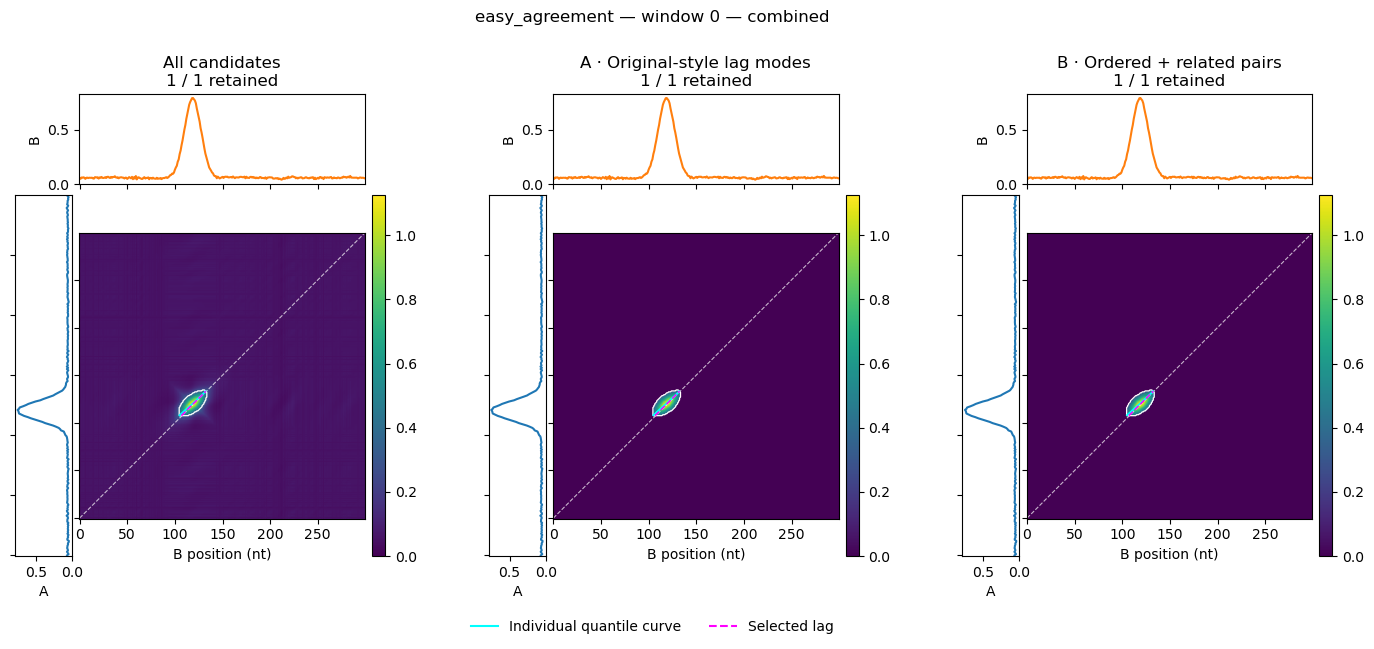

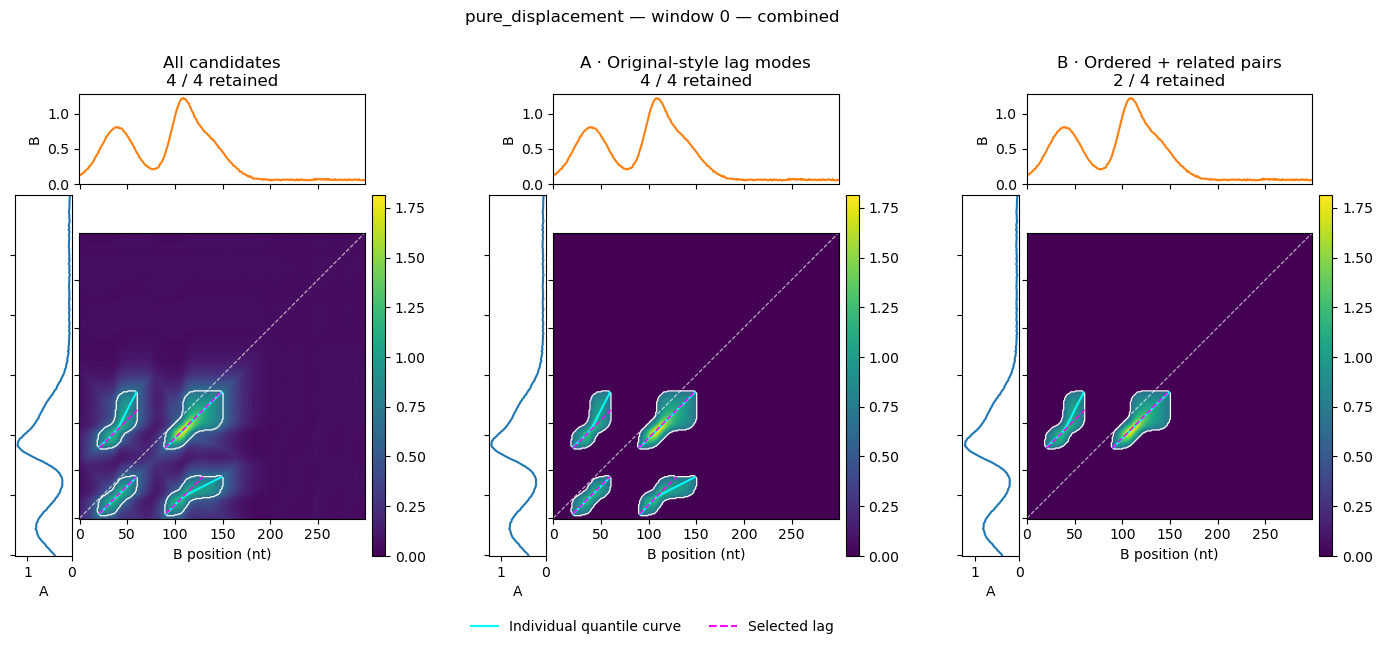

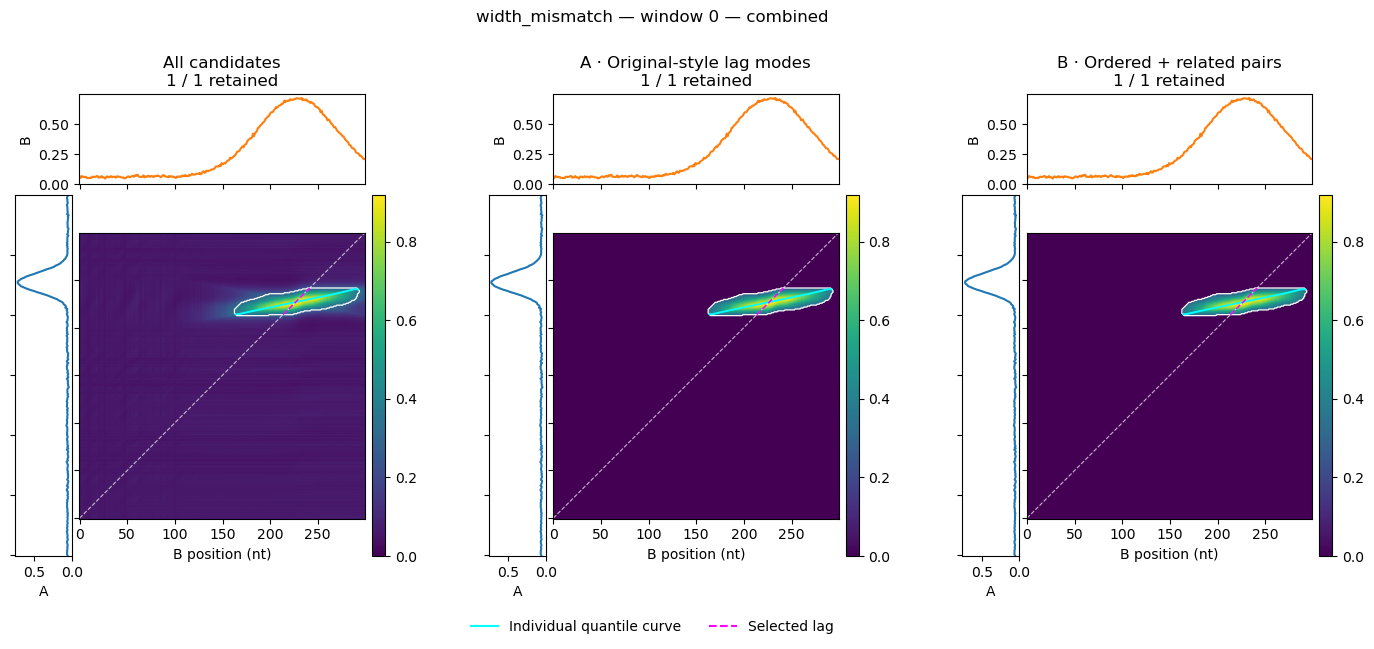

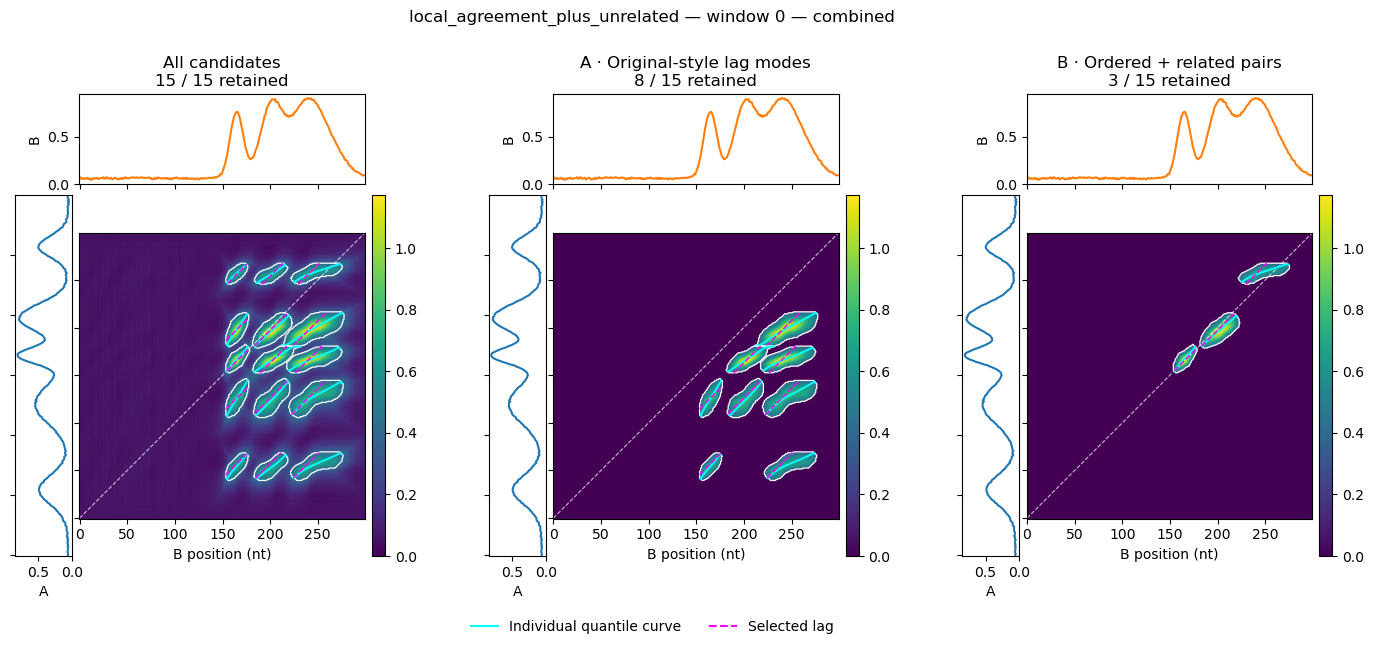

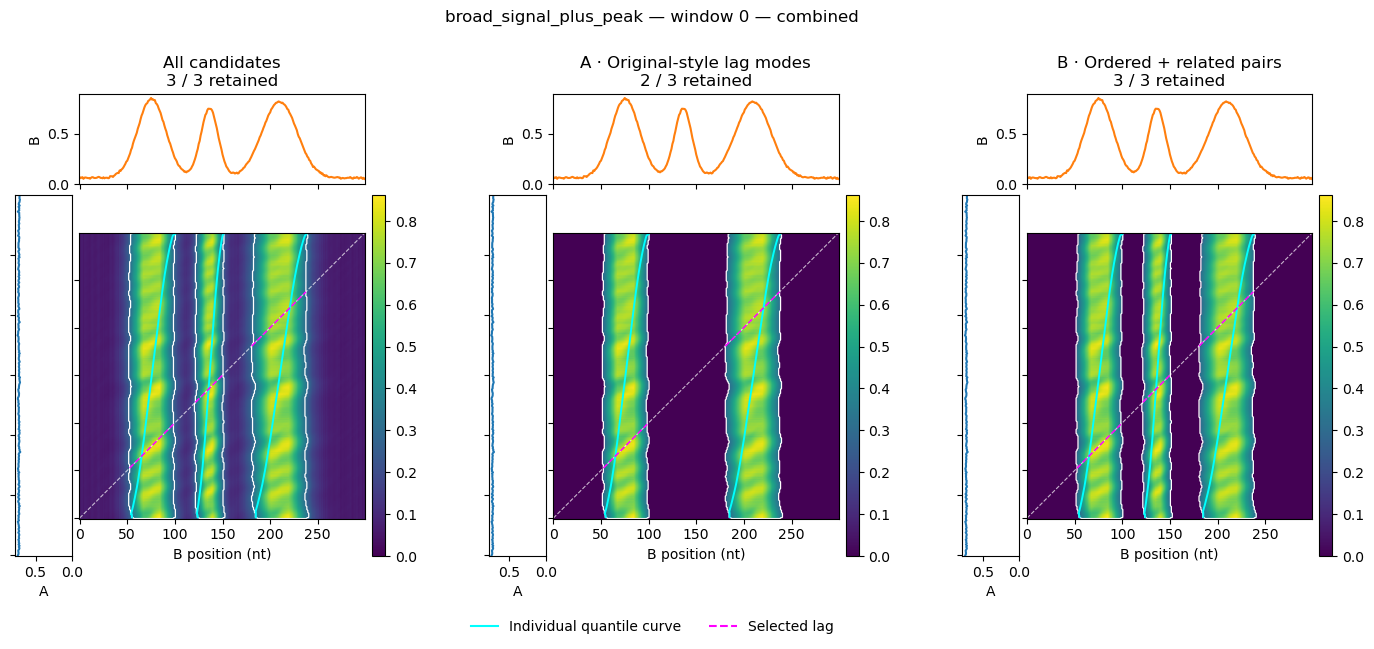

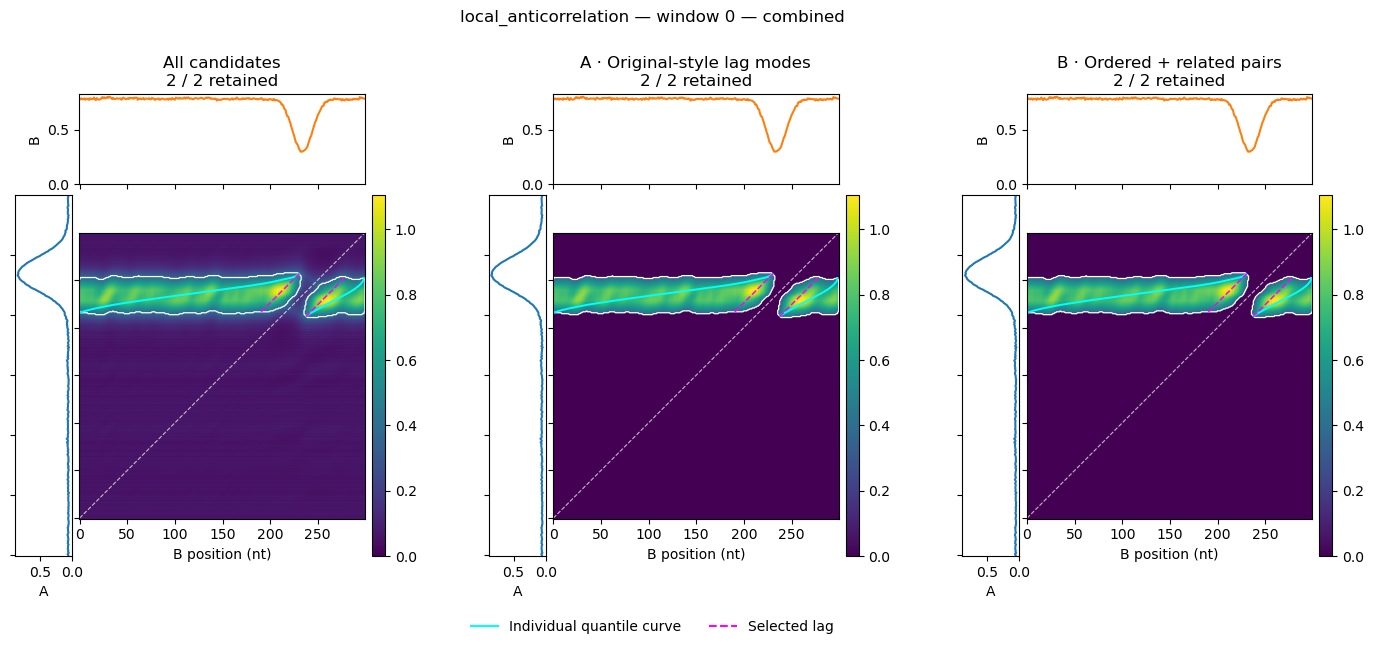

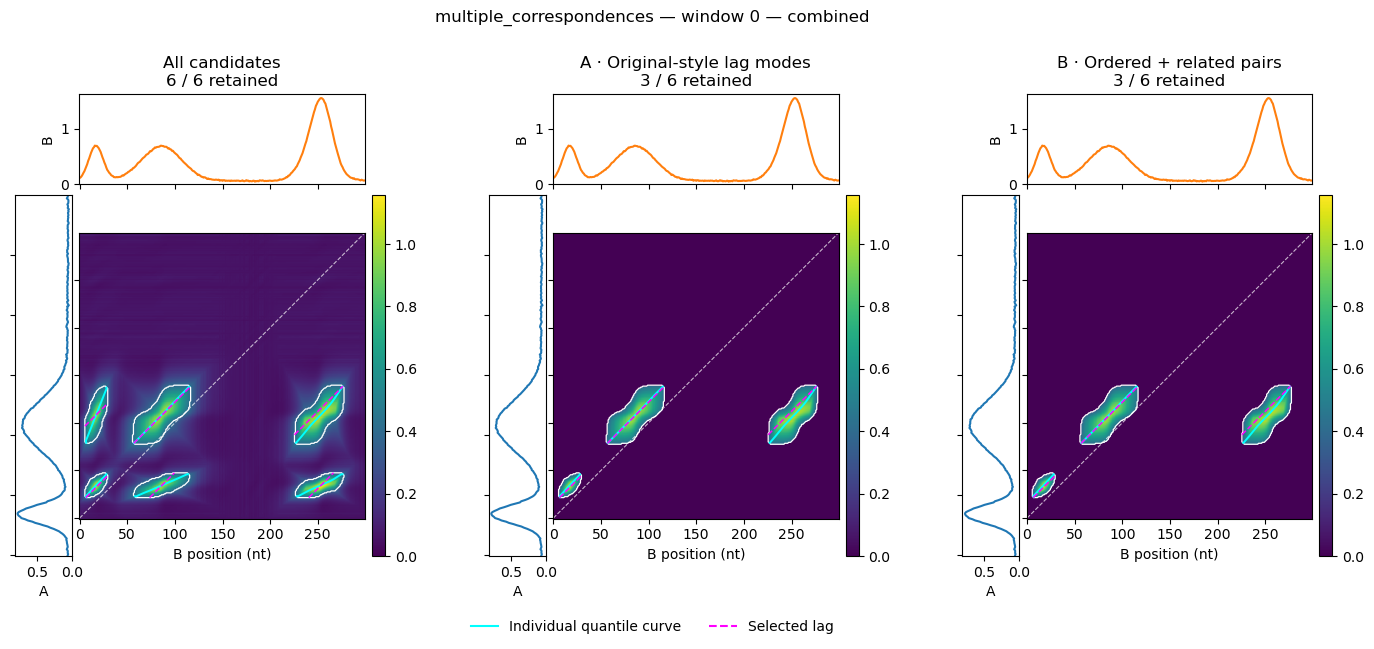

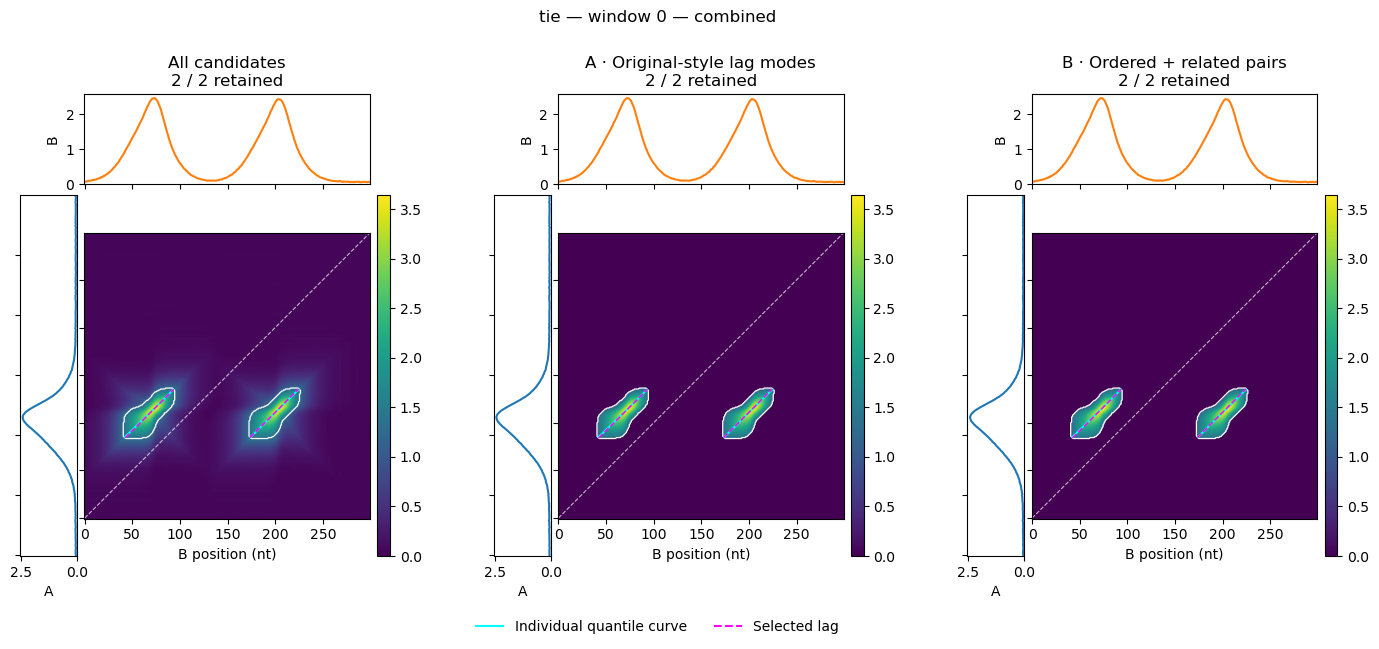

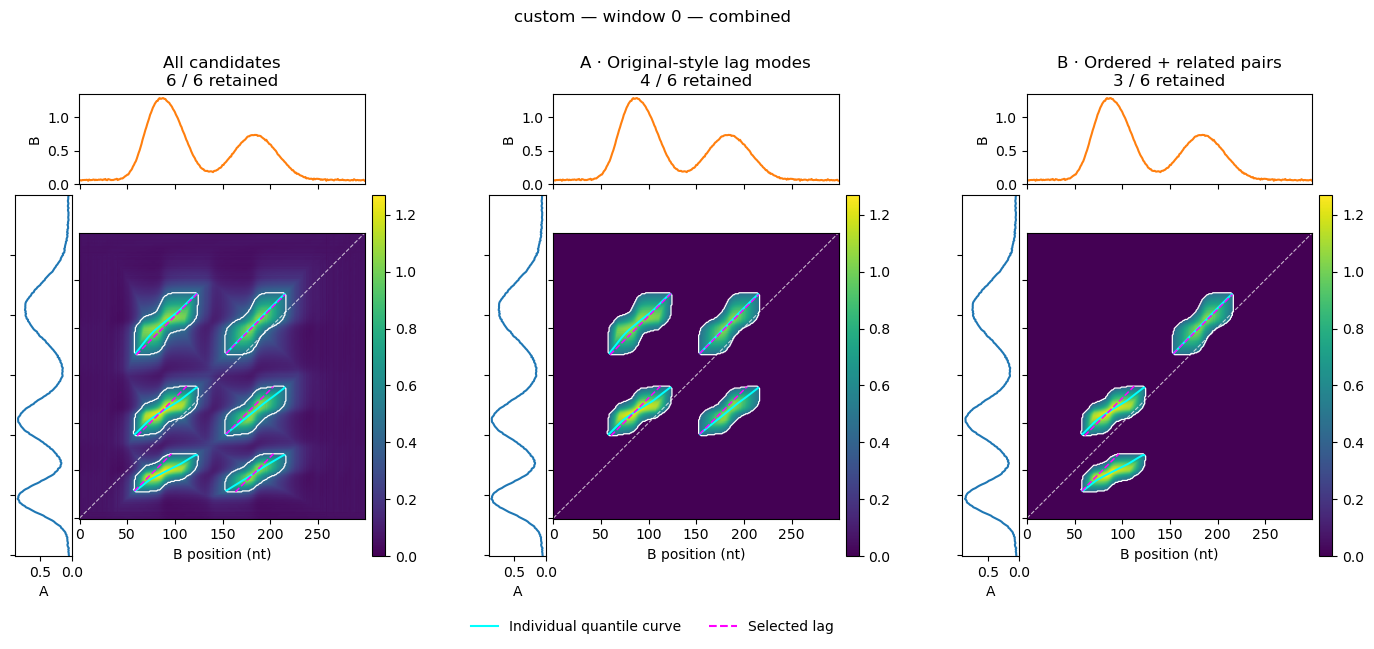

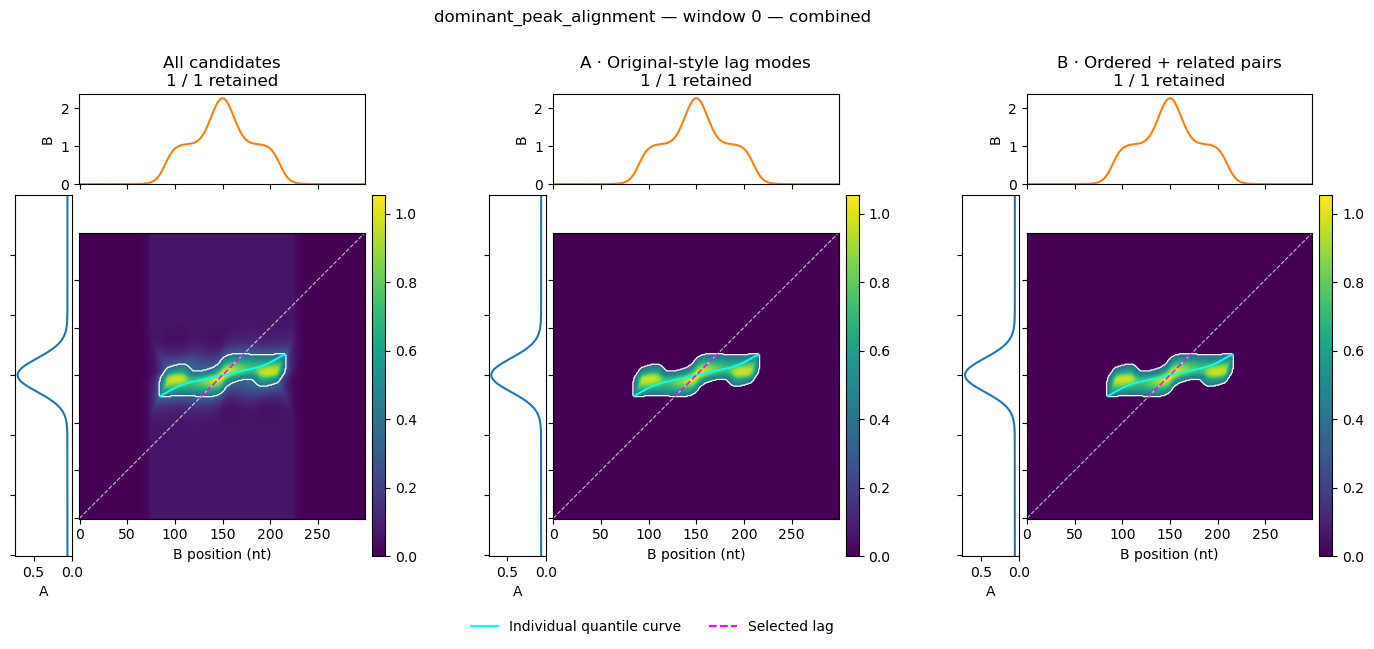

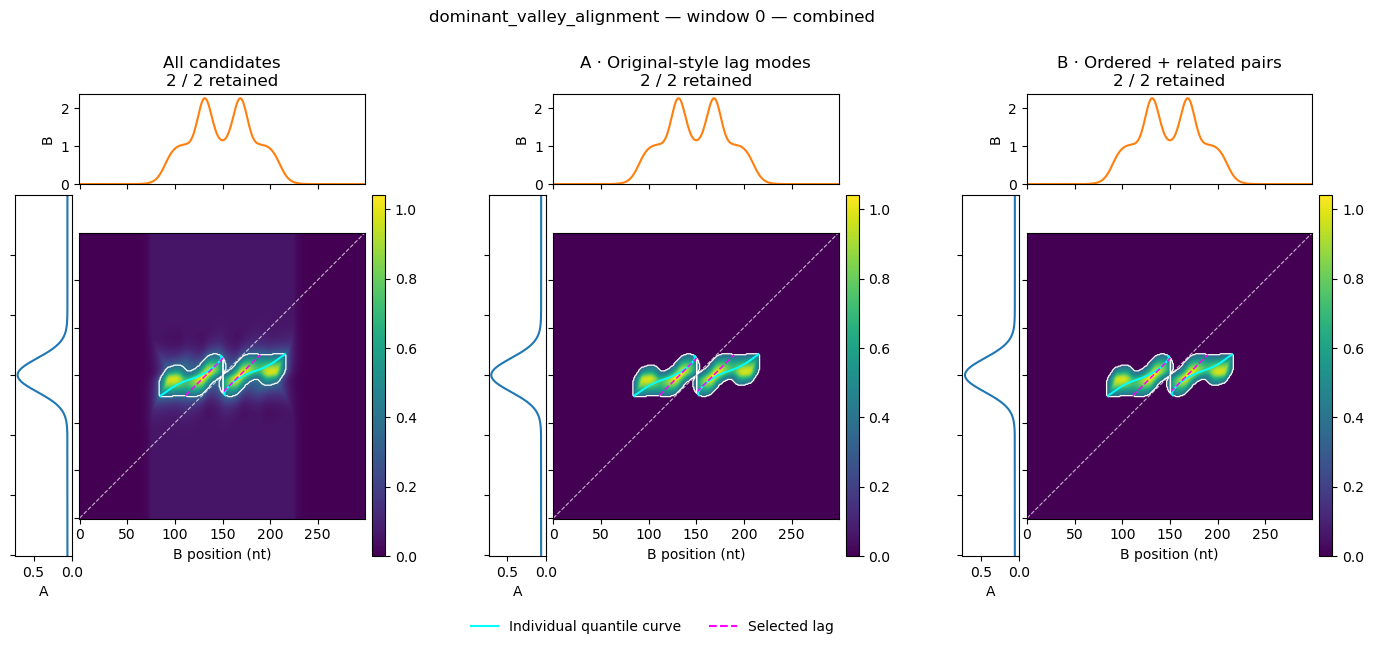

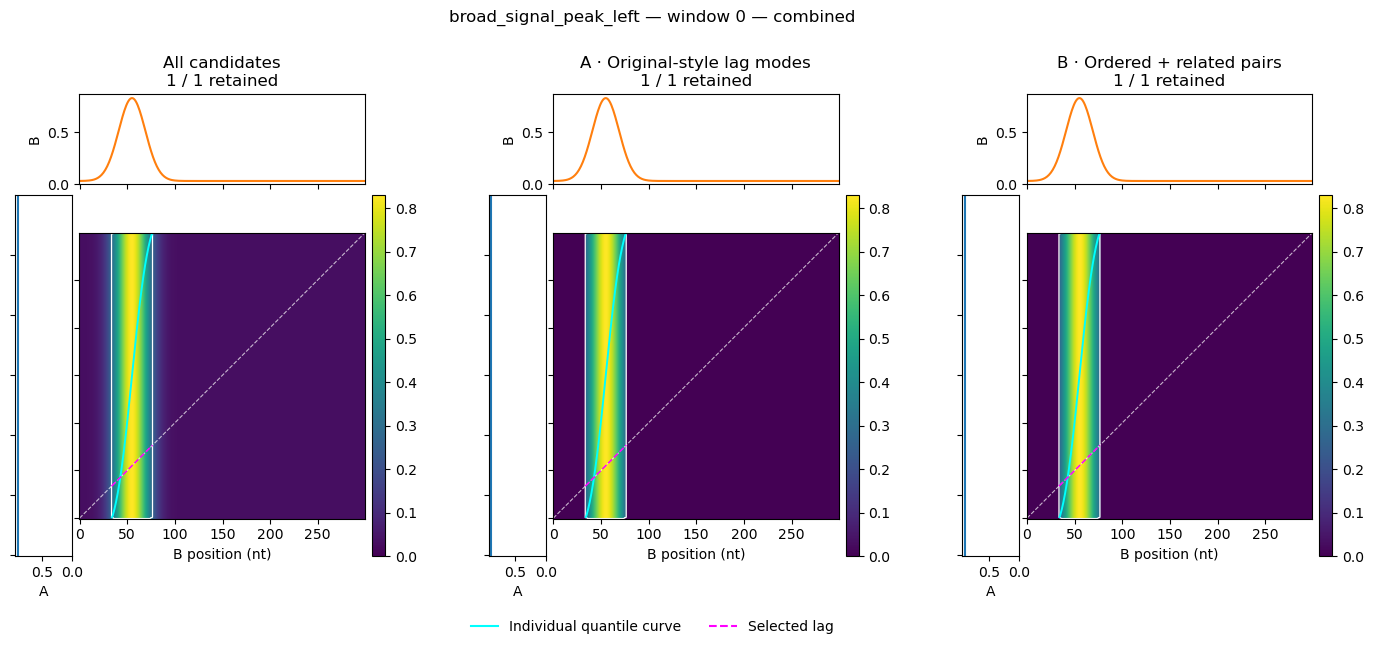

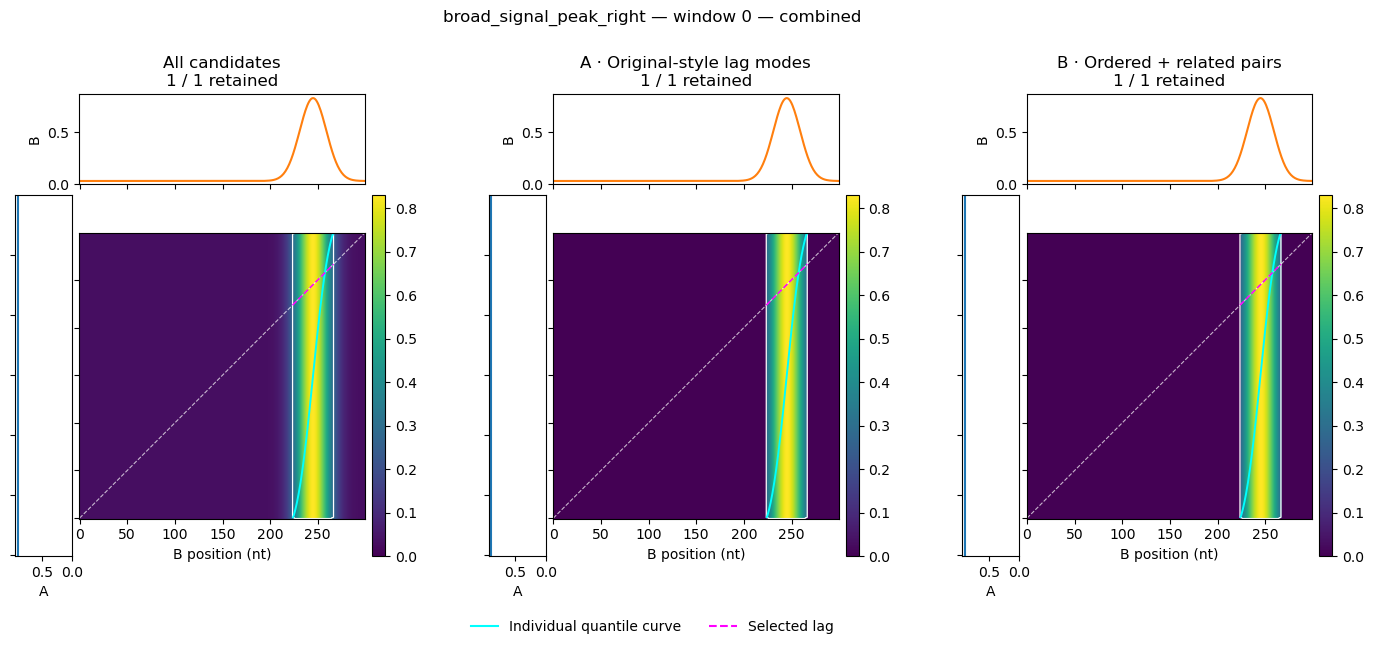

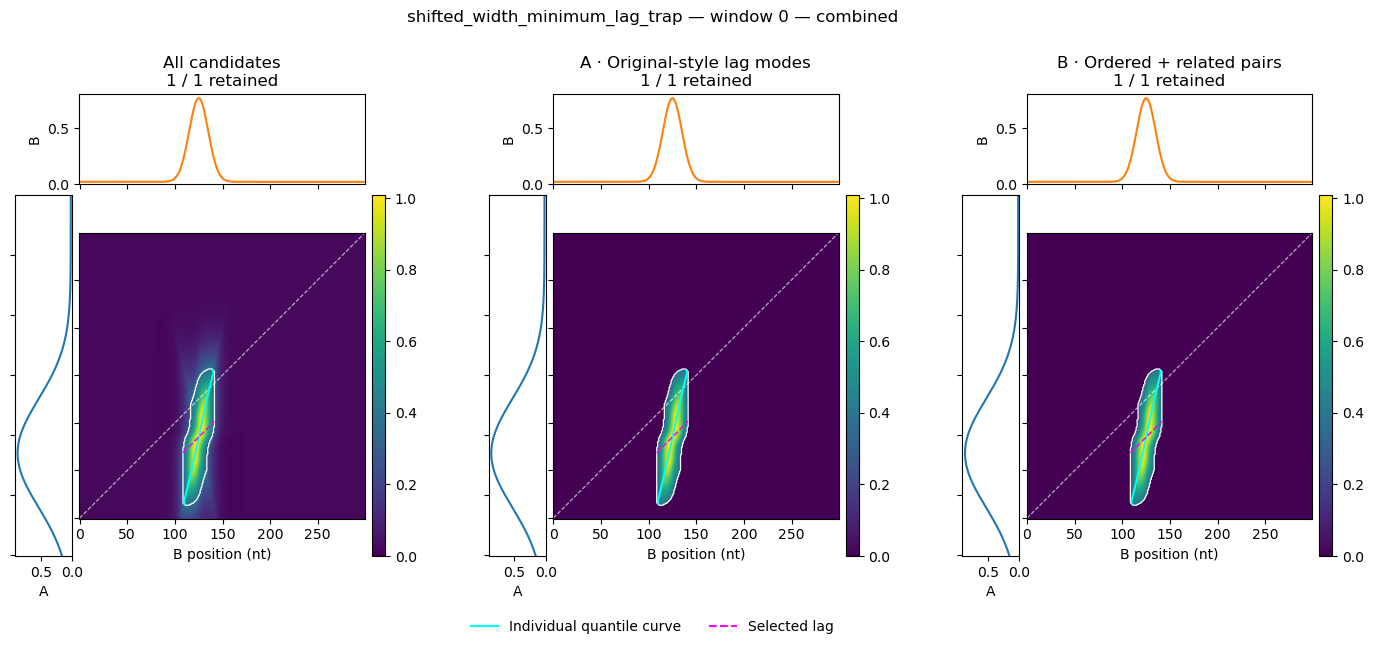

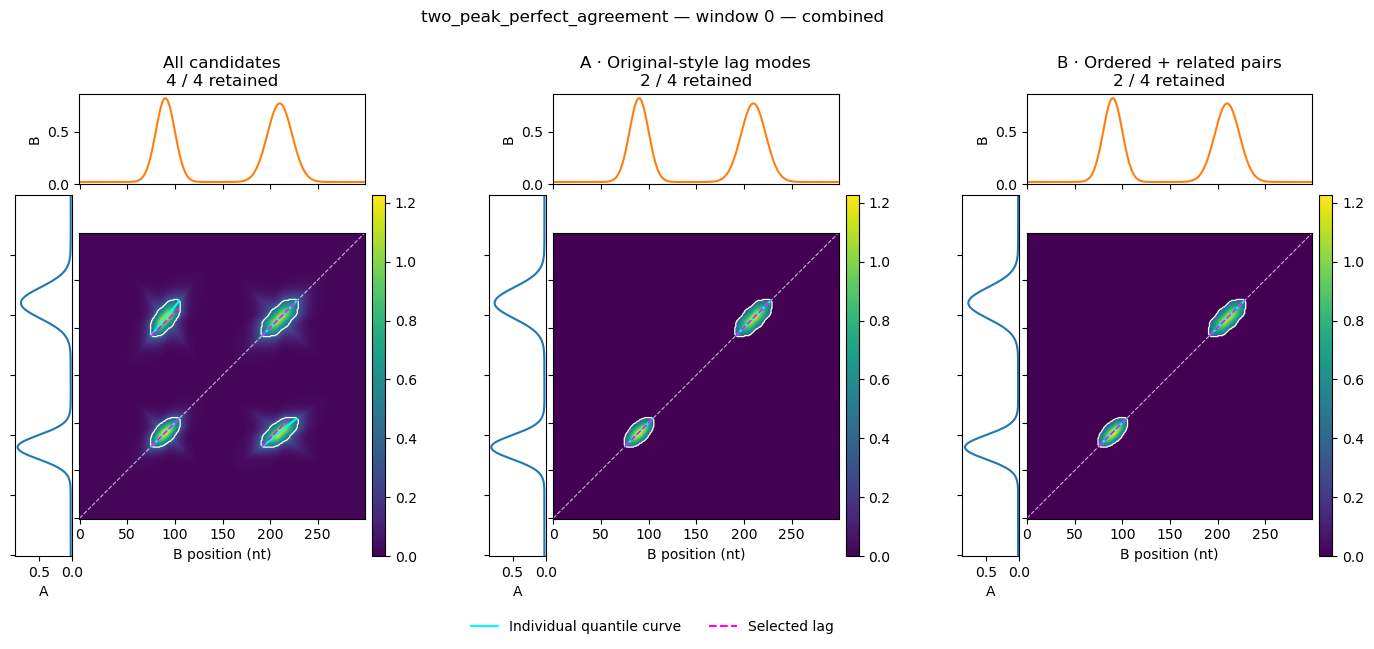

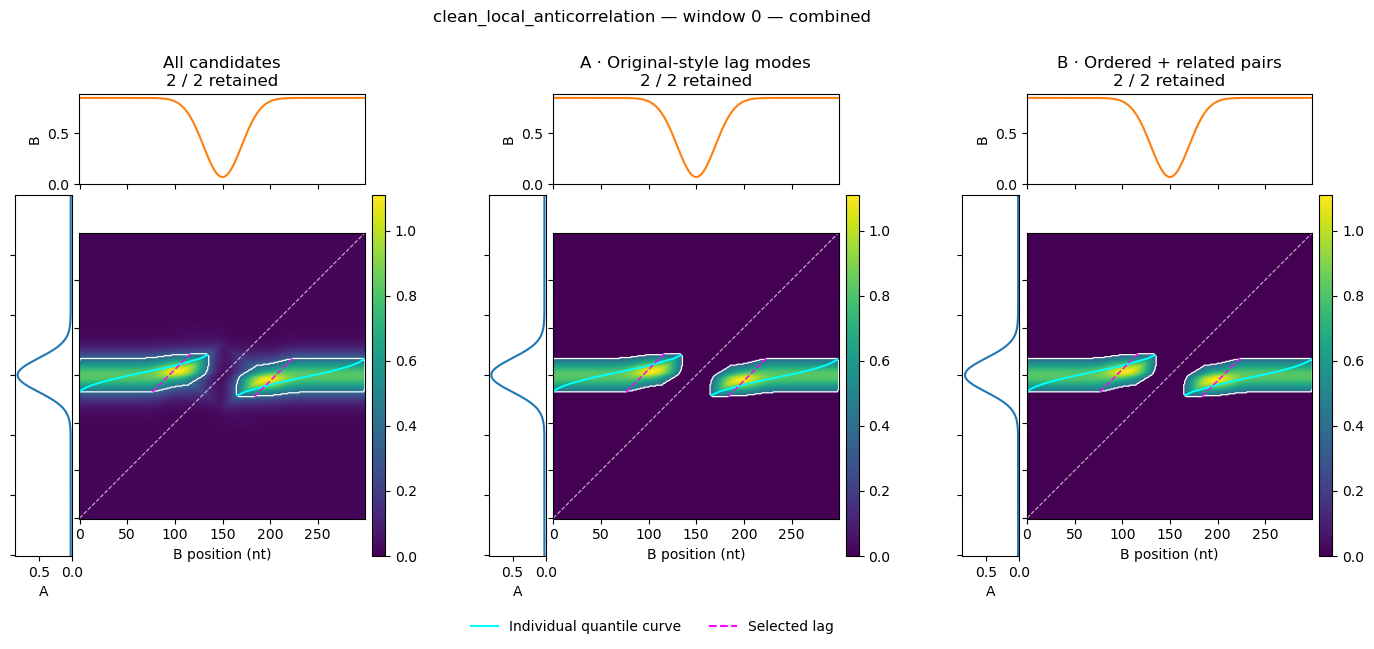

In [57]:
if SHOW_SELECTION_COMPARISONS:
    plot_selection_results()

## Displacement controls

The off-center pillars should retain their minimum lag. In the stress case, A and B peak centers differ by **+40 nt**. The minimum matrix can have a plateau of equally good shifts; the combined matrix may give a more specific best shift.

`best_relative_gain` is a fraction: 0.10 means a 10% improvement over the minimum-displacement baseline. This table describes split candidates; unsplit plots are computed separately when requested.

In [58]:
displacement_comparison

,scenario,matrix,region_id,selected_lag_b_minus_a,selected_diagonal_score,best_relative_gain,displacement_status
159,broad_signal_peak_left,minimum,1,0.0,25.868198,0.000000,minimum_retained
160,broad_signal_peak_left,combined,1,0.0,25.868198,0.000000,minimum_retained
161,broad_signal_peak_right,minimum,1,0.0,25.868198,0.000000,minimum_retained
162,broad_signal_peak_right,combined,1,0.0,25.868198,0.000000,minimum_retained
163,shifted_width_minimum_lag_trap,minimum,1,0.0,15.274708,0.122457,minimum_retained
164,shifted_width_minimum_lag_trap,combined,1,40.0,23.898274,0.704830,improved


In [59]:
if SHOW_DISPLACEMENT_PROFILES:
    plot_displacement_profiles()

## Simulated tracks

In [60]:
if SHOW_TRACK_OVERVIEW:
    plot_simulated_tracks()

## Optional original matrix overview

Enable `SHOW_MATRIX_OVERVIEW` to restore the previous minimum / shape / combined plots. Pairwise warning colors are off by default.

In [61]:
if SHOW_MATRIX_OVERVIEW:
    plot_matrix_results()

## Individual candidate measurements

In [62]:
selection_members.merge(candidate_metrics[
    ["scenario", "window_idx", "matrix", "region_id", "selected_lag_b_minus_a", "selected_diagonal_score"]],
    on=["scenario", "window_idx", "matrix", "region_id"], how="left", validate="many_to_one")

,scenario,window_idx,matrix,method,region_id,retained,reason,selected_lag_b_minus_a,selected_diagonal_score
0,easy_agreement,0,minimum,legacy_modes,1,True,retained_lag_mode,-1.000000,14.031077
1,easy_agreement,0,minimum,ordered_pairs,1,True,ordered_chain,-1.000000,14.031077
2,easy_agreement,0,combined,legacy_modes,1,True,retained_lag_mode,-0.634036,20.604381
3,easy_agreement,0,combined,ordered_pairs,1,True,ordered_chain,-0.634036,20.604381
4,easy_agreement,1,minimum,legacy_modes,1,True,retained_lag_mode,-1.822621,34.456672
...,...,...,...,...,...,...,...,...,...
349,clean_local_anticorrelation,0,minimum,ordered_pairs,2,True,straddling_pair,37.000000,23.072198
350,clean_local_anticorrelation,0,combined,legacy_modes,1,True,retained_lag_mode,56.000000,29.157059
351,clean_local_anticorrelation,0,combined,legacy_modes,2,True,retained_lag_mode,-56.000000,29.157059
352,clean_local_anticorrelation,0,combined,ordered_pairs,1,True,straddling_pair,56.000000,29.157059


<details>
<summary>Calculation notes and inspection examples</summary>

### Displacement scoring

For each candidate mask, sum its matrix signal along every integer B−A diagonal. Pixels outside that mask contribute zero. Scores are **sums**, not means: a short supported diagonal does not win just because it omits weaker positions. The minimum-|lag| point on the visible quantile curve defines the baseline; its score is linearly interpolated between adjacent integer-diagonal scores if its lag is fractional. All supported integer lags are checked, so the search cannot get trapped at a local optimum.

Retain that baseline unless `best_score > baseline_score × (1 + minimum_relative_gain)`. Numerical ties are treated as ties, not improvements. If the baseline score is zero, any positive best score clears this relative threshold. No extra gain floor is added.

The selected score is **candidate-conditioned total support**, not a probability or confidence interval. Window-edge truncation and candidate boundaries can affect it. Equal best scores can leave a broad ambiguity range even though one representative lag is reported. Displacements are evaluated independently; order preservation and no-merging constraints are not yet imposed.

### Unchanged calculations

The original random scenarios keep their seed and random-number order. Additional deterministic controls compare dominant peak/valley structure, off-center peaks under flat signal, and shifted broad/narrow peaks.

The shape score compares locally centered profiles and slope profiles after shape-only smoothing. Minimum support uses the original tracks. Combined support remains `minimum × (1 + shape_strength × shape)`.

Candidate detection retains the original binary closing, seed restoration, hole filling, and 8-connectivity. Thresholds scale to each matrix's own maximum. Recursive splitting uses the original axis-profile valleys and the visible parameter settings.

Quantile curves use candidate-masked marginals and the existing projection/clipping helpers. Minimum absolute lag is calculated on continuous visible curve segments, without bridging gaps. The minimum and previous median values remain available in `candidate_metrics` for diagnostics, but are not plotted or included in the default result tables. The box-relative perpendicular offset is not window-coordinate displacement.

### Selection trial limitations

Trial A copies the original mode selector's decisions: maximal overlapping original ridge-lag intervals, full interval-constrained region sums, bounding-box shape balance, the central/displaced fold gate, and the global mode-score fraction. Final membership is the union of final retained modes. Full original candidate masks and curves are displayed afterward. It can still retain mutually incompatible displaced modes when the central gate does not resolve them.

Trial B uses exact dynamic programming over ordered interval nodes. Singleton weight is selected-diagonal support plus `zero_lag_bonus × zero_lag_score`. Adjacent nodes must occupy nonoverlapping, consistently ordered matched intervals on both axes; touching boundaries are allowed. There is no global strongest-window cutoff, fixed shared lag, or explicit reward for island count.

An optional related-pair node contains two candidates with opposite selected-lag signs, shared A or B support, and overlapping matched intervals. The node reserves their combined A/B spans; both candidates retain their own measurements. This can preserve anti-correlation-like pieces, but can also join unrelated opposite-lag structures and exclude intervening correspondences. It is a hypothesis to inspect, not a biological classification. Three-way configurations are not bundled.

The optimizer holds each candidate's accepted lag fixed. It does not search joint alternative lags. Scores are sums of per-region support, not a conserved mass allocation; related pieces may reuse a track's positions. These limitations are intentional and inspectable in `selection_results` and `selection_members`.

### Diagnostic interpretation

The full candidate projections supply conservative ordering evidence; selected diagonal extents are reported separately. These warnings are conditional on treating two regions as distinct simultaneous direct matches, not proofs of biological incompatibility. Overlap, opposite lag signs, and shared split-parent IDs never cause deletion.

Zero-lag support is the actual sum on the candidate's zero diagonal, not simply whether its selected lag is zero. Its ratio to the candidate's best diagonal score controls only the green display; it adds no bonus or selection rule. A low-score candidate can still have a high ratio. No new scientific threshold is introduced.

Set `SHOW_CANDIDATE_DIAGNOSTICS=False` to restore white boundaries without warnings. `SHOW_REGION_IDS` and `SHOW_ZERO_LAG_SUPPORT` control only the diagnostic display. Raw candidate counts, masks, selected lags, and scores are unchanged.

### Inspect one example

`plot_matrix_comparison("shifted_width_minimum_lag_trap", 0)`

`plot_matrix_comparison("broad_signal_peak_left", 0, candidate_stage="unsplit")`

`candidate_metrics.query('scenario == "local_anticorrelation"')`

</details>